# Load files

/var/folders/2q/_tgbc5bj1gd3yszdck0wkrjm0000gn/T/ipykernel_77972/911002813.py:152: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax1.legend(loc="upper left")


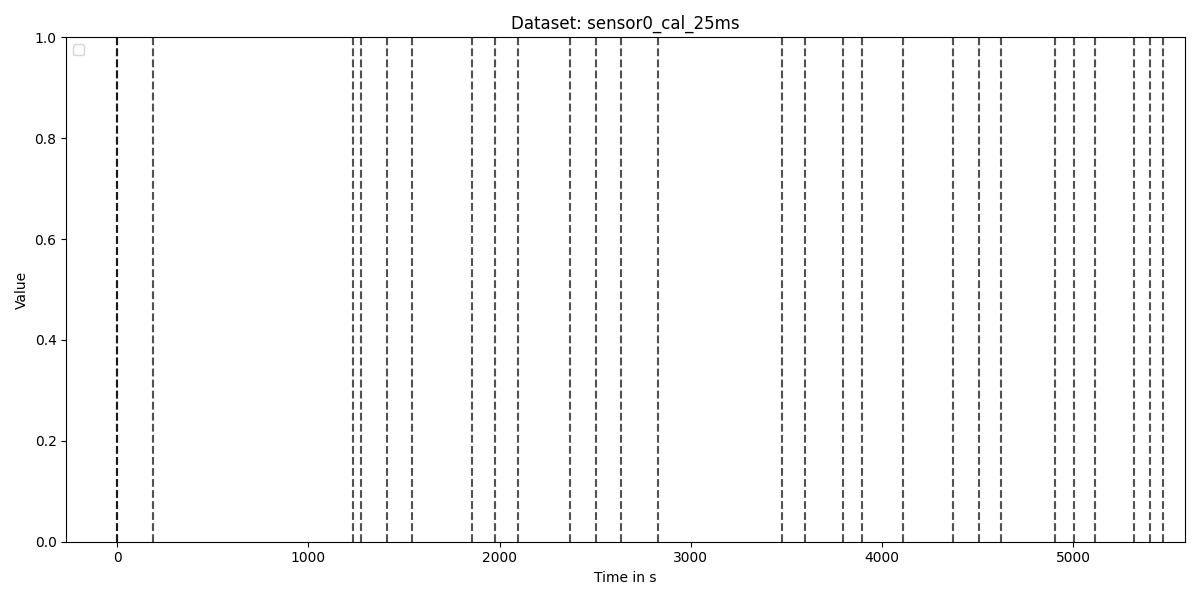

Markers for sensor0_cal_25ms:
     0.000 s, Text: STEP_1: Start sensor (upstream)
     0.102 s, Text: STEP_2: Wait (20 min warmup)
   186.050 s, Text: Marker No.
  1234.641 s, Text: STEP_3: Warte auf Stop (Calibration)
  1274.794 s, Text: H20 - 1
  1411.092 s, Text: H20 - 2
  1544.221 s, Text: H20 - 3
  1854.196 s, Text: C002 - 1
  1975.126 s, Text: C002 - 2
  2096.595 s, Text: C002 - 3
  2367.328 s, Text: C005 - 1
  2506.228 s, Text: C005 - 2
  2635.048 s, Text: C005 - 3
  2825.703 s, Text: C010 - 1
  3475.018 s, Text: C010 - 2
  3598.070 s, Text: C010 - 3
  3792.887 s, Text: C025 - 1
  3894.731 s, Text: C025 - 2
  4108.425 s, Text: C025 - 3
  4368.498 s, Text: C050 - 1
  4506.880 s, Text: C050 - 2
  4623.213 s, Text: C050 - 3
  4901.613 s, Text: C075 - 1
  5002.698 s, Text: C075 - 2
  5110.303 s, Text: C075 - 3
  5317.562 s, Text: C100 - 1
  5401.941 s, Text: C100 - 2
  5466.098 s, Text: C100 - 3


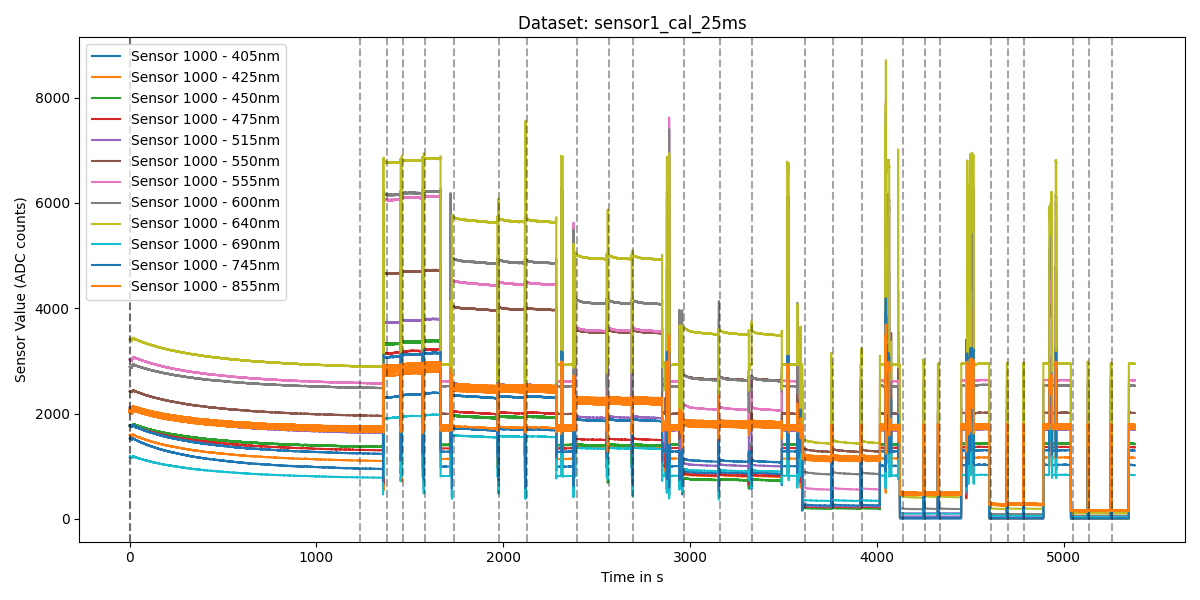

Markers for sensor1_cal_25ms:
     0.000 s, Text: STEP_1: Start sensor (upstream)
     0.029 s, Text: STEP_2: Wait (20 min warmup)
  1234.062 s, Text: STEP_3: Warte auf Stop (Calibration)
  1376.683 s, Text: H20 - 1
  1462.935 s, Text: H20 - 2
  1578.925 s, Text: H20 - 3
  1737.889 s, Text: C002 - 1
  1978.124 s, Text: C002 - 2
  2125.215 s, Text: C002 - 3
  2395.266 s, Text: C005 - 1
  2565.128 s, Text: C005 - 2
  2695.581 s, Text: C005 - 3
  2965.643 s, Text: C010 - 1
  3157.690 s, Text: C010 - 2
  3333.318 s, Text: C010 - 3
  3612.835 s, Text: C025 - 1
  3764.702 s, Text: C025 - 2
  3920.432 s, Text: C025 - 3
  4139.873 s, Text: C050 - 1
  4255.648 s, Text: C050 - 2
  4335.636 s, Text: C050 - 3
  4612.839 s, Text: C075 - 1
  4703.043 s, Text: C075 - 2
  4789.236 s, Text: C075 - 3
  5046.898 s, Text: C100 - 1
  5135.738 s, Text: C100 - 2
  5260.058 s, Text: C100 - 3


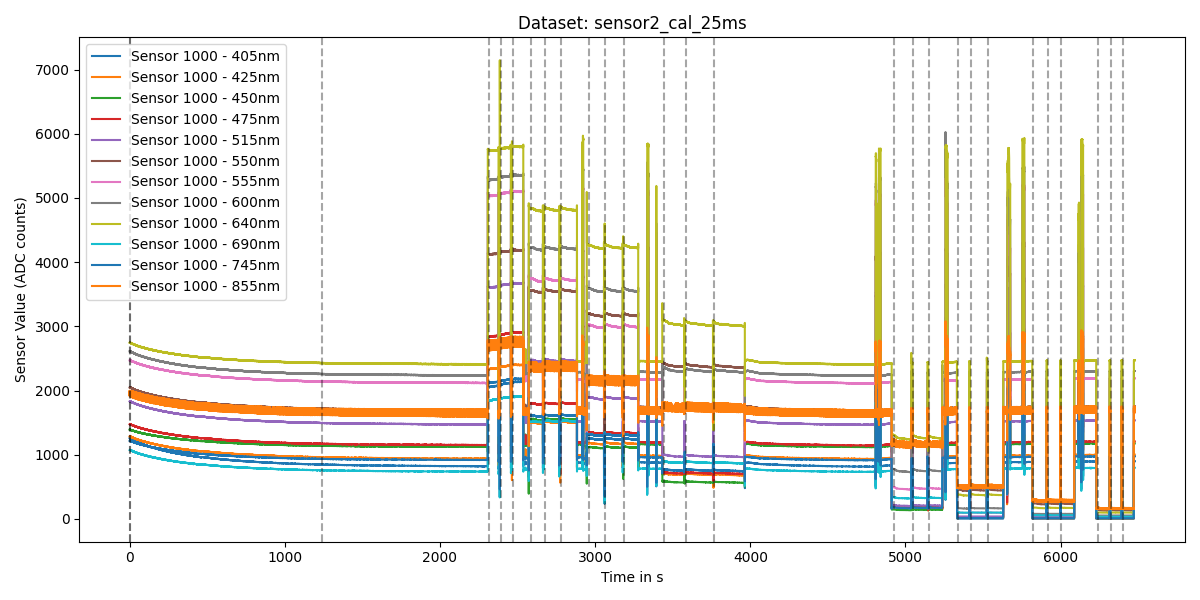

Markers for sensor2_cal_25ms:
     0.000 s, Text: STEP_1: Start sensor (upstream)
     0.074 s, Text: STEP_2: Wait (20 min warmup)
  1236.468 s, Text: STEP_3: Warte auf Stop (Calibration)
  2317.131 s, Text: H20 - 1
  2392.289 s, Text: H20 - 2
  2468.440 s, Text: H20 - 3
  2584.806 s, Text: C002 - 1
  2675.892 s, Text: C002 - 2
  2778.563 s, Text: C002 - 3
  2963.501 s, Text: C005 - 1
  3065.724 s, Text: C005 - 2
  3185.078 s, Text: C005 - 3
  3442.592 s, Text: C010 - 1
  3582.274 s, Text: C010 - 2
  3765.608 s, Text: C010 - 3
  4926.816 s, Text: C025 - 1
  5050.873 s, Text: C025 - 2
  5151.708 s, Text: C025 - 3
  5340.512 s, Text: C050 - 1
  5419.729 s, Text: C050 - 2
  5532.160 s, Text: C050 - 3
  5824.257 s, Text: C075 - 1
  5916.348 s, Text: C075 - 2
  6005.091 s, Text: C075 - 3
  6239.169 s, Text: C100 - 1
  6323.266 s, Text: C100 - 2
  6400.276 s, Text: C100 - 3


In [9]:
%matplotlib widget

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from typing import Dict, Optional

file_paths = {
    'sensor0_cal_25ms': '../experiments/E01_sensor_calibration/data/Sensor0_Messung_20260421_103826/Markers_20260421_103826.csv',
    'sensor0_marker': '../experiments/E01_sensor_calibration/data/Sensor0_Messung_20260421_103826/Markers_20260421_103826.csv',
    'sensor1_cal_25ms': '../experiments/E01_sensor_calibration/data/Sensor1_Messung_20260421_124824/SpectralSensor 1_20260421_124824.csv',
    'sensor1_marker': '../experiments/E01_sensor_calibration/data/Sensor1_Messung_20260421_124824/Markers_20260421_124824.csv',
    'sensor2_cal_25ms': '../experiments/E01_sensor_calibration/data/Sensor2_Messung_20260421_142354/SpectralSensor 1_20260421_142354.csv',
    'sensor2_marker': '../experiments/E01_sensor_calibration/data/Sensor2_Messung_20260421_142354/Markers_20260421_142354.csv',
}

wavelengths = ['405', '425', '450', '475', '515', '550', '555', '600', '640', '690', '745', '720', '855']


class DataAnalyzer:
    def __init__(self, base_path: str = ".", wavelengths: Optional[list] = None):
        self.base_path = base_path
        self.wavelengths = wavelengths or []
        self.datasets: Dict[str, pd.DataFrame] = {}
        self.groupeds: Dict[str, pd.core.groupby.DataFrameGroupBy] = {}
        self.first_timestamps: Dict[str, float] = {}
        self.marker_map: Dict[str, str] = {}

    def _fullpath(self, rel: str) -> str:
        return os.path.join(self.base_path, rel)

    def _dataset_prefix(self, key: str) -> str:
        return key.split('_')[0]

    def _is_marker_key(self, key: str) -> bool:
        return 'marker' in key.lower()

    def load_and_prepare(self, rel_path: str):
        path = self._fullpath(rel_path)
        df = pd.read_csv(path)

        # Vereinheitliche Quellformate aus verschiedenen Projekten.
        if 'sensor' in df.columns and 'device' not in df.columns:
            df = df.rename(columns={'sensor': 'device'})
        if 'marker_id' in df.columns and 'device' not in df.columns:
            df = df.rename(columns={'marker_id': 'device'})
        if 'label' in df.columns and '405' not in df.columns:
            df['405'] = df['label']

        if 'device' in df.columns:
            non_marker = pd.to_numeric(df['device'], errors='coerce') != 99
            for wl in self.wavelengths:
                if wl in df.columns:
                    df.loc[non_marker, wl] = pd.to_numeric(df.loc[non_marker, wl], errors='coerce')
        else:
            for wl in self.wavelengths:
                if wl in df.columns:
                    df[wl] = pd.to_numeric(df[wl], errors='coerce')

        df['timestamp_raw'] = pd.to_numeric(df['timestamp'], errors='coerce')

        if 'device' in df.columns:
            df['device'] = pd.to_numeric(df['device'], errors='coerce').astype('Int64')

        return df

    def load_files(self, mapping: Dict[str, str]):
        self.datasets.clear()
        self.groupeds.clear()
        self.first_timestamps.clear()
        self.marker_map.clear()

        for key, rel in mapping.items():
            self.datasets[key] = self.load_and_prepare(rel)

        marker_by_prefix = {
            self._dataset_prefix(key): key
            for key in mapping.keys()
            if self._is_marker_key(key)
        }

        for key in mapping.keys():
            prefix = self._dataset_prefix(key)
            if not self._is_marker_key(key) and prefix in marker_by_prefix:
                self.marker_map[key] = marker_by_prefix[prefix]

        for prefix in {self._dataset_prefix(k) for k in mapping.keys()}:
            keys_for_prefix = [k for k in mapping.keys() if self._dataset_prefix(k) == prefix]
            ts_candidates = []
            for key in keys_for_prefix:
                ts_min = self.datasets[key]['timestamp_raw'].min()
                if pd.notna(ts_min):
                    ts_candidates.append(float(ts_min))

            if not ts_candidates:
                continue

            ref_ts_ms = min(ts_candidates)
            for key in keys_for_prefix:
                df = self.datasets[key]
                df['timestamp'] = (df['timestamp_raw'] - ref_ts_ms) / 1000.0
                df.drop(columns=['timestamp_raw'], inplace=True)
                self.first_timestamps[key] = ref_ts_ms / 1000.0

                if 'device' in df.columns:
                    self.groupeds[key] = df.groupby('device', dropna=True)

    def plot_dataset(
        self,
        key: str,
        title: Optional[str] = None,
        device_ids: Optional[list] = None,
        wl_filter: Optional[list] = None,
        show_markers: bool = True,
    ):
        if key not in self.groupeds:
            raise KeyError(key)

        grouped = self.groupeds[key]
        fig, ax1 = plt.subplots(figsize=(12, 6))
        any_sensor = False
        wls = wl_filter or self.wavelengths

        for device_id, group in grouped:
            if pd.isna(device_id):
                continue

            device_id_int = int(device_id)

            if device_id_int == 99:
                if show_markers:
                    for ts in group['timestamp']:
                        ax1.axvline(x=ts, color='k', linestyle='--', alpha=0.5)
                continue

            if device_ids is not None and device_id_int not in device_ids:
                continue

            any_sensor = True
            for wl in wls:
                if wl in group.columns:
                    series = pd.to_numeric(group[wl], errors='coerce')
                    ax1.plot(group['timestamp'], series, label=f"Sensor {device_id_int} - {wl}nm")

        if show_markers:
            for ts, _ in self.extract_markers(key):
                ax1.axvline(x=ts, color='k', linestyle='--', alpha=0.35)

        ax1.set_xlabel("Time in s")
        ax1.set_ylabel("Sensor Value (ADC counts)" if any_sensor else "Value")
        ax1.legend(loc="upper left")
        plt.title(title or key)
        plt.tight_layout()
        plt.show()

    def extract_markers(self, key: str):
        marker_rows = []

        if key in self.groupeds:
            for device_id, group in self.groupeds[key]:
                if pd.isna(device_id) or int(device_id) != 99:
                    continue
                for _, row in group.iterrows():
                    text = row.get('405', None)
                    if isinstance(text, str) and text.strip():
                        marker_rows.append((float(row['timestamp']), text.strip()))

        marker_key = self.marker_map.get(key)
        if marker_key and marker_key in self.datasets:
            df = self.datasets[marker_key]
            if {'timestamp', '405'}.issubset(df.columns):
                for _, row in df.iterrows():
                    text = row.get('405', None)
                    if isinstance(text, str) and text.strip():
                        marker_rows.append((float(row['timestamp']), text.strip()))

        deduped = {(round(ts, 6), text) for ts, text in marker_rows}
        return sorted(deduped, key=lambda x: x[0])

    def print_markers(self, key: str):
        markers = self.extract_markers(key)
        print(f"Markers for {key}:")
        for ts, text in markers:
            print(f"  {ts:8.3f} s, Text: {text}")

    def calculate_snr(self, key: str, t1_h2o: float, t2_h2o: float, t1_spion: float, t2_spion: float):
        if key not in self.groupeds:
            raise KeyError(key)

        snr_results = {}
        for device_id, group in self.groupeds[key]:
            if pd.isna(device_id) or int(device_id) == 99:
                continue

            device_key = int(device_id)
            snr_results[device_key] = {}

            for wl in self.wavelengths:
                if wl not in group.columns:
                    snr_results[device_key][wl] = np.nan
                    continue

                series = pd.to_numeric(group[wl], errors='coerce')
                h2o = series[(group['timestamp'] >= t1_h2o) & (group['timestamp'] <= t2_h2o)]
                spion = series[(group['timestamp'] >= t1_spion) & (group['timestamp'] <= t2_spion)]

                mean_h2o = h2o.mean()
                mean_spion = spion.mean()
                noise = np.sqrt((h2o.std() or 0) ** 2 + (spion.std() or 0) ** 2)

                if noise == 0 or np.isnan(noise):
                    snr_results[device_key][wl] = np.nan
                else:
                    snr = (mean_h2o - mean_spion) / noise
                    snr_results[device_key][wl] = 20 * np.log10(snr) if snr > 0 else np.nan

        return snr_results

    def plot_snr(self, snr_results, title: Optional[str] = None):
        plt.figure(figsize=(10, 6))
        for device_id, wl_snr in snr_results.items():
            wls = [int(w) for w in wl_snr.keys()]
            vals = list(wl_snr.values())
            plt.plot(wls, vals, marker='o', label=f"Sensor {device_id}")

        plt.title(title or "SNR vs Wavelength")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()


# --- Beispiel direkt ausführen ---
analyzer = DataAnalyzer(base_path=".", wavelengths=wavelengths)
analyzer.load_files(file_paths)

sensor_keys = [k for k in file_paths if 'marker' not in k.lower()]
for key in sensor_keys:
    analyzer.plot_dataset(key, f"Dataset: {key}")
    analyzer.print_markers(key)

In [10]:
# 60 Sekunden nach jedem Marker pro Sensor als separates Dictionary
# marker_windows_by_sensor[sensor_key][marker_key] -> DataFrame

window_seconds = 57.0
marker_windows_by_sensor = {}

for target_key in sensor_keys:
    markers = analyzer.extract_markers(target_key)
    sensor_df = analyzer.datasets[target_key].copy()

    # Marker-Events selbst aus den Ausschnitten entfernen (falls vorhanden)
    if 'device' in sensor_df.columns:
        sensor_df = sensor_df[sensor_df['device'] != 99]

    marker_windows_60s = {}
    key_counter = {}

    for ts, marker_text in markers:
        clean_key = ''.join(str(marker_text).split())
        if not clean_key:
            continue

        # Doppelte Markertexte eindeutig machen
        idx = key_counter.get(clean_key, 0) + 1
        key_counter[clean_key] = idx
        unique_key = clean_key if idx == 1 else f"{clean_key}_{idx}"

        snippet = sensor_df[
            (sensor_df['timestamp'] >= ts)
            & (sensor_df['timestamp'] < ts + window_seconds)
        ].copy()

        marker_windows_60s[unique_key] = snippet

    marker_windows_by_sensor[target_key] = marker_windows_60s

print(f"Erstellt fuer {len(marker_windows_by_sensor)} Sensoren jeweils 60s-Markerfenster.")
for sensor_key, windows in marker_windows_by_sensor.items():
    print(f"  {sensor_key}: {len(windows)} Fenster")

marker_windows_by_sensor

Erstellt fuer 3 Sensoren jeweils 60s-Markerfenster.
  sensor0_cal_25ms: 28 Fenster
  sensor1_cal_25ms: 27 Fenster
  sensor2_cal_25ms: 27 Fenster


{'sensor0_cal_25ms': {'STEP_1:Startsensor(upstream)': Empty DataFrame
  Columns: [device, timestamp, label, 405]
  Index: [],
  'STEP_2:Wait(20minwarmup)': Empty DataFrame
  Columns: [device, timestamp, label, 405]
  Index: [],
  'MarkerNo.': Empty DataFrame
  Columns: [device, timestamp, label, 405]
  Index: [],
  'STEP_3:WarteaufStop(Calibration)': Empty DataFrame
  Columns: [device, timestamp, label, 405]
  Index: [],
  'H20-1': Empty DataFrame
  Columns: [device, timestamp, label, 405]
  Index: [],
  'H20-2': Empty DataFrame
  Columns: [device, timestamp, label, 405]
  Index: [],
  'H20-3': Empty DataFrame
  Columns: [device, timestamp, label, 405]
  Index: [],
  'C002-1': Empty DataFrame
  Columns: [device, timestamp, label, 405]
  Index: [],
  'C002-2': Empty DataFrame
  Columns: [device, timestamp, label, 405]
  Index: [],
  'C002-3': Empty DataFrame
  Columns: [device, timestamp, label, 405]
  Index: [],
  'C005-1': Empty DataFrame
  Columns: [device, timestamp, label, 405]
  I


Einzelmarker-Statistik sensor0_cal_25ms @ 640 nm


""


Keine vollstaendigen 3er-Gruppen fuer sensor0_cal_25ms gefunden.

Einzelmarker-Statistik sensor1_cal_25ms @ 640 nm


,sensor_key,marker,mean,std,min,max
0,sensor1_cal_25ms,STEP_1:Startsensor(upstream),3404.231383,17.174895,3373.0,3442.0
1,sensor1_cal_25ms,STEP_2:Wait(20minwarmup),3404.191235,17.198793,3373.0,3442.0
2,sensor1_cal_25ms,STEP_3:WarteaufStop(Calibration),2896.954907,1.864061,2892.0,2902.0
3,sensor1_cal_25ms,H20-1,6768.765252,3.377421,6758.0,6781.0
4,sensor1_cal_25ms,H20-2,6810.379310,2.707894,6803.0,6819.0
5,sensor1_cal_25ms,H20-3,6842.657825,3.180643,6832.0,6851.0
6,sensor1_cal_25ms,C002-1,5693.598143,13.282868,5673.0,5724.0
7,sensor1_cal_25ms,C002-2,5672.836870,13.441474,5653.0,5713.0
8,sensor1_cal_25ms,C002-3,5668.271883,10.077341,5651.0,5696.0
9,sensor1_cal_25ms,C005-1,4975.104775,15.188795,4953.0,5007.0



Gruppen-Statistik sensor1_cal_25ms (Mittel aus 3 Replikaten) @ 640 nm


,marker_group,n,mean,std,min,max
0,H20,3,6807.267462,37.044443,6768.765252,6842.657825
1,C002,3,5678.235632,13.498698,5668.271883,5693.598143
2,C005,3,4970.298408,4.190951,4967.407162,4975.104775
3,C010,3,3550.678603,24.720912,3529.583554,3577.880637
4,C025,3,1467.780283,6.281868,1460.927056,1473.265252
5,C050,3,419.967286,3.464529,416.001326,422.404509
6,C075,3,195.668877,0.877650,194.904509,196.627321
7,C100,3,112.470822,0.874886,111.472149,113.102122


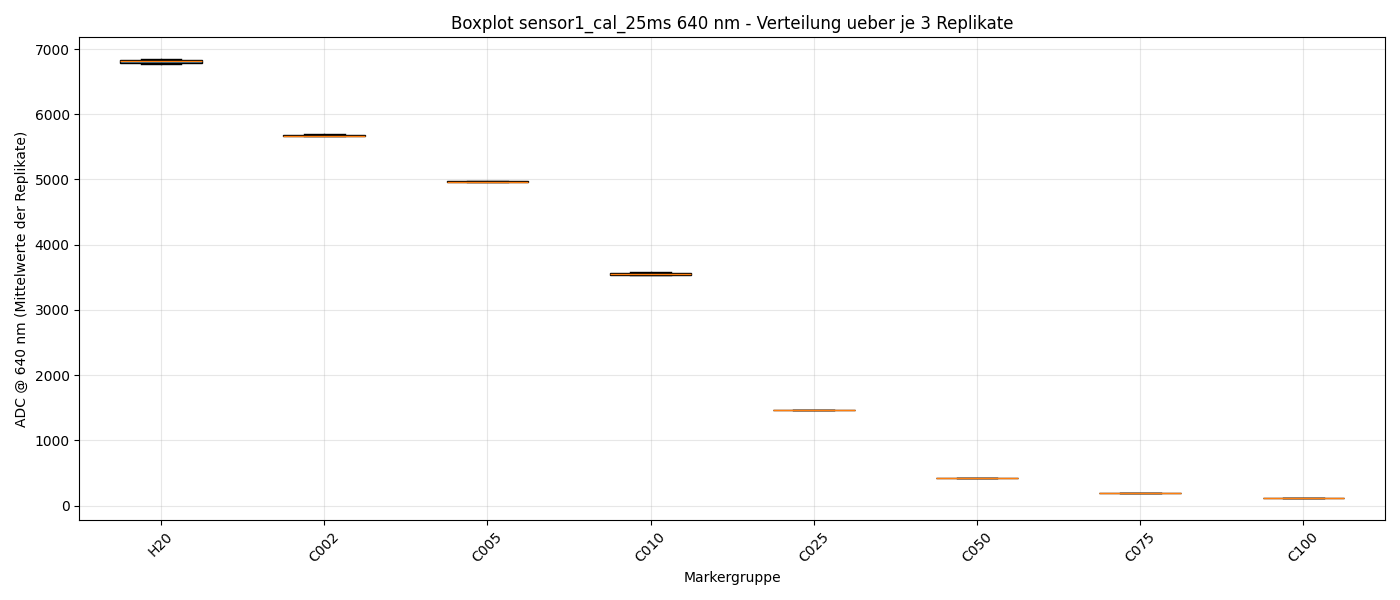


Einzelmarker-Statistik sensor2_cal_25ms @ 640 nm


,sensor_key,marker,mean,std,min,max
0,sensor2_cal_25ms,STEP_1:Startsensor(upstream),2718.245308,17.012988,2689.0,2752.0
1,sensor2_cal_25ms,STEP_2:Wait(20minwarmup),2718.207497,17.032961,2689.0,2752.0
2,sensor2_cal_25ms,STEP_3:WarteaufStop(Calibration),2427.885180,1.497826,2424.0,2432.0
3,sensor2_cal_25ms,H20-1,5738.072096,2.980352,5730.0,5746.0
4,sensor2_cal_25ms,H20-2,5777.985314,3.520156,5769.0,5788.0
5,sensor2_cal_25ms,H20-3,5800.321762,3.651506,5791.0,5811.0
6,sensor2_cal_25ms,C002-1,4817.869159,14.638111,4795.0,4843.0
7,sensor2_cal_25ms,C002-2,4828.684913,11.241850,4808.0,4853.0
8,sensor2_cal_25ms,C002-3,4832.441923,10.812990,4814.0,4857.0
9,sensor2_cal_25ms,C005-1,4241.178905,14.574354,4219.0,4270.0



Gruppen-Statistik sensor2_cal_25ms (Mittel aus 3 Replikaten) @ 640 nm


,marker_group,n,mean,std,min,max
0,H20,3,5772.126391,31.535702,5738.072096,5800.321762
1,C002,3,4826.331998,7.565945,4817.869159,4832.441923
2,C005,3,4245.167334,3.931214,4241.178905,4249.038718
3,C010,3,3053.351580,9.255332,3043.064085,3061.002670
4,C025,3,1272.135291,4.294671,1267.869159,1276.457944
5,C050,3,376.431687,4.433231,371.333778,379.383178
6,C075,3,173.686693,0.424166,173.428571,174.176235
7,C100,3,100.655541,0.216712,100.504673,100.903872


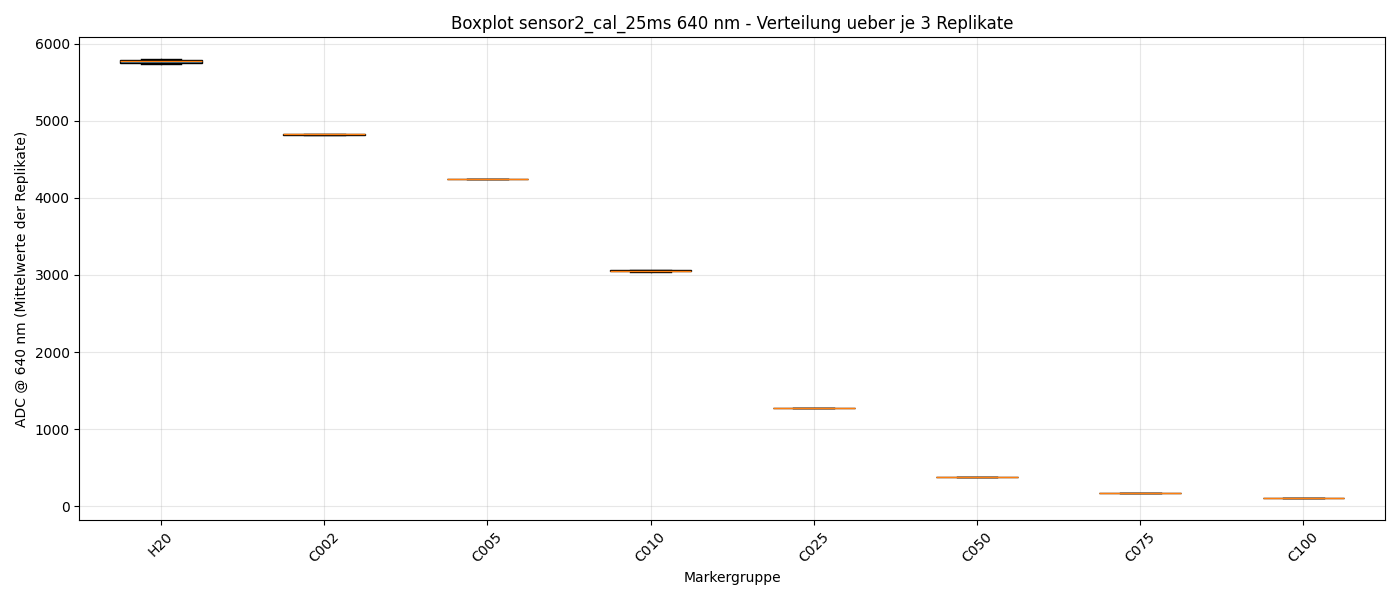


Gruppenstatistiken fuer 2 Sensoren erstellt: ['sensor1_cal_25ms', 'sensor2_cal_25ms']


In [11]:
import re

selected_wavelength = '640'   # hier z. B. auf '550' oder '690' aendern
expected_replicates = 3

if selected_wavelength not in wavelengths:
    raise ValueError(f"Wellenlaenge {selected_wavelength} nicht in wavelengths.")

if 'marker_windows_by_sensor' not in globals():
    raise RuntimeError("Bitte zuerst die Markerfenster-Zelle ausfuehren.")

# Ergebnisse pro Sensor sammeln
group_stats_by_sensor = {}

for sensor_key in sensor_keys:
    marker_windows_60s = marker_windows_by_sensor.get(sensor_key, {})

    # --- Einzelmarker-Statistik ---
    individual_rows = []
    samples_by_group = {}
    group_order = []

    for marker_key, snippet_df in marker_windows_60s.items():
        if snippet_df.empty or selected_wavelength not in snippet_df.columns:
            continue

        series = pd.to_numeric(snippet_df[selected_wavelength], errors='coerce').dropna()
        if series.empty:
            continue

        mean_val = float(series.mean())
        std_val = float(series.std(ddof=1)) if len(series) > 1 else 0.0
        min_val = float(series.min())
        max_val = float(series.max())

        individual_rows.append({
            'sensor_key': sensor_key,
            'marker': marker_key,
            'mean': mean_val,
            'std': std_val,
            'min': min_val,
            'max': max_val,
        })

        m = re.match(r'^(.*)-([0-9]+)$', marker_key)
        if not m:
            continue

        group = m.group(1)
        if group not in samples_by_group:
            samples_by_group[group] = []
            group_order.append(group)
        samples_by_group[group].append(mean_val)

    individual_stats = pd.DataFrame(individual_rows)
    print(f"\nEinzelmarker-Statistik {sensor_key} @ {selected_wavelength} nm")
    display(individual_stats)

    # --- Gruppen-Statistik (Mittel ueber Replikate) ---
    rows = []
    ignored_groups = {}

    for group in group_order:
        vals = samples_by_group[group]
        if len(vals) != expected_replicates:
            ignored_groups[group] = vals
            continue

        rows.append({
            'marker_group': group,
            'n': len(vals),
            'mean': float(np.mean(vals)),
            'std': float(np.std(vals, ddof=1)) if len(vals) > 1 else 0.0,
            'min': float(np.min(vals)),
            'max': float(np.max(vals)),
        })

    if not rows:
        print(f"Keine vollstaendigen 3er-Gruppen fuer {sensor_key} gefunden.")
        continue

    group_stats = pd.DataFrame(rows)
    group_stats_by_sensor[sensor_key] = group_stats

    print(f"\nGruppen-Statistik {sensor_key} (Mittel aus {expected_replicates} Replikaten) @ {selected_wavelength} nm")
    display(group_stats)

    if ignored_groups:
        print("\nIgnorierte Gruppen (nicht genau 3 Stichproben):")
        for group, vals in ignored_groups.items():
            print(f"  {group}: n={len(vals)}, Werte={vals}")

    # --- Boxplot pro Sensor ---
    complete_groups = [g for g in group_order if len(samples_by_group[g]) == expected_replicates]
    box_data = [samples_by_group[g] for g in complete_groups]

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.boxplot(box_data, tick_labels=complete_groups, patch_artist=True)
    ax.set_xlabel('Markergruppe')
    ax.set_ylabel(f'ADC @ {selected_wavelength} nm (Mittelwerte der Replikate)')
    ax.set_title(f'Boxplot {sensor_key} {selected_wavelength} nm - Verteilung ueber je {expected_replicates} Replikate')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

if not group_stats_by_sensor:
    raise RuntimeError("Fuer keinen Sensor konnten vollstaendige Gruppen gebildet werden.")

print(f"\nGruppenstatistiken fuer {len(group_stats_by_sensor)} Sensoren erstellt: {list(group_stats_by_sensor.keys())}")

# Fitting Curve


## Was hier gemacht wird

In diesem Abschnitt wird ein **exponentielles Beer-Lambert-Modell** an die Kalibrierdaten gefittet.

### Physikalischer Zusammenhang (Beer-Lambert)

Allgemein gilt fuer die Transmission durch ein absorbierendes Medium:

$$
I = I_0 \cdot e^{-\mu_a \cdot l}
$$

mit
- $I_0$: eingestrahlte Intensitaet,
- $I$: gemessene Intensitaet nach Durchgang,
- $\mu_a$: effektiver Absorptionskoeffizient,
- $l$: optische Weglaenge.

Mit $\mu_a = k \cdot c$ (proportional zur Partikelkonzentration $c$) folgt:

$$
I(c) = I_0 \cdot e^{-k l \cdot c} = I_0 \cdot e^{-\alpha c}, \quad \alpha = k l
$$

Genau diese Form wird hier gefittet.

### Umformung fuer die Konzentrationsfunktion

Aus

$$
I(c) = I_0 \cdot e^{-\alpha c}
$$

folgt durch Logarithmieren:

$$
\ln\!\left(\frac{I}{I_0}\right) = -\alpha c
$$

und damit

$$
c(I) = -\frac{1}{\alpha} \ln\!\left(\frac{I}{I_0}\right)
$$

Die aktuelle Auswertung nutzt den Fit in Vorwaertsrichtung $I(c)$; die Rueckrechnung ist hier bewusst nicht Teil der Plots.

### Messhintergrund dieser Daten

- Gemessen wurde die Partikelkonzentration in einem Schlauch mit **3.17 mm Durchmesser**.
- Die Auswertung erfolgt mit einem **multispektralen Sensor**.
- Betrachtet wird das **640 nm Band**, weil es in den vorangegangenen Analysen die hoechste SNR gezeigt hat.
- Dadurch liefert der exponentielle Fit pro Sensor eine robuste Kalibrierfunktion $I(c)$.

### Ablauf in den Zellen

1. Markerfenster werden fuer **alle Sensoren** aufgebaut.
2. Pro Sensor werden Mean-ADC-Werte je Markergruppe berechnet.
3. Mit `scipy.optimize.curve_fit` werden pro Sensor die zwei Modellparameter $I_0$ und $\alpha$ bestimmt.
4. Pro Sensor werden Fit-Qualitaet ($R^2$) und Fit-Funktion ausgegeben.

Plots:
- Pro Sensor ein ADC-gegen-Konzentration-Plot mit exponentieller Fit-Kurve.

,marker,concentration_pct,mean_adc
0,H20,0.0,6807.267462
1,C002,2.5,5678.235632
2,C005,5.0,4970.298408
3,C010,10.0,3550.678603
4,C025,25.0,1467.780283
5,C050,50.0,419.967286
6,C075,75.0,195.668877
7,C100,100.0,112.470822


sensor1_cal_25ms -> Fit-Parameter: I0 = 6723.7152, alpha = 0.061603, R^2 = 0.9988
sensor1_cal_25ms -> Funktion: I(c) = 6723.7152 * exp(-0.061603 * c)


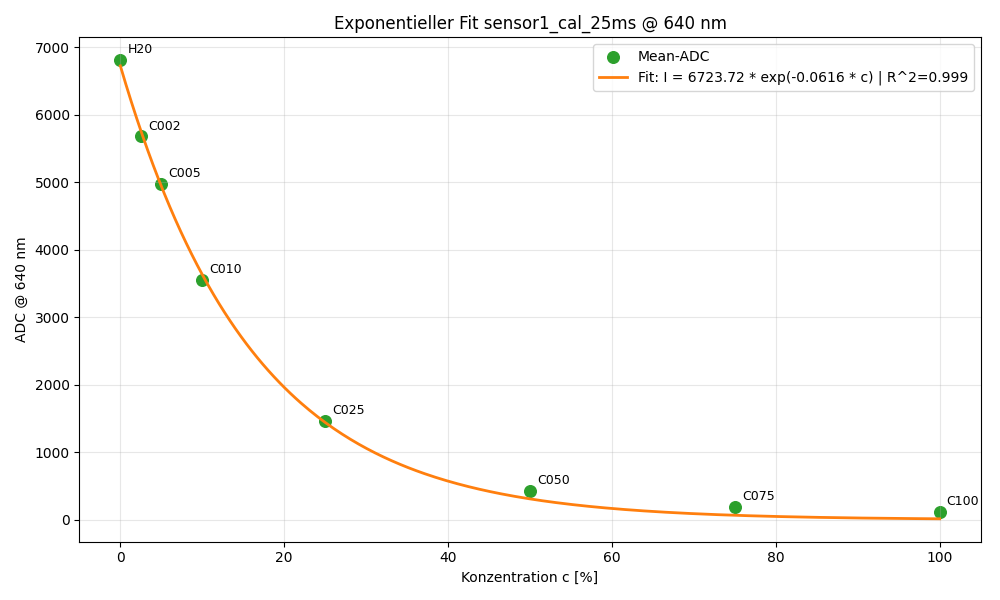

,marker,concentration_pct,mean_adc
0,H20,0.0,5772.126391
1,C002,2.5,4826.331998
2,C005,5.0,4245.167334
3,C010,10.0,3053.351580
4,C025,25.0,1272.135291
5,C050,50.0,376.431687
6,C075,75.0,173.686693
7,C100,100.0,100.655541


sensor2_cal_25ms -> Fit-Parameter: I0 = 5701.0885, alpha = 0.060345, R^2 = 0.9988
sensor2_cal_25ms -> Funktion: I(c) = 5701.0885 * exp(-0.060345 * c)


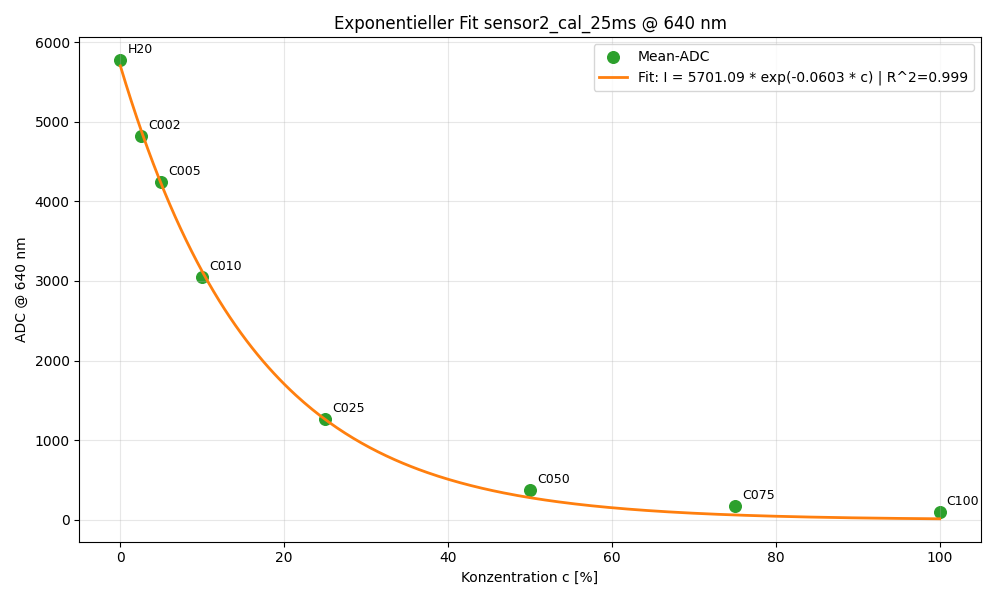


Fertig. Exponentielle Konzentrationsfunktionen pro Sensor:
  sensor1_cal_25ms: I(c) = 6723.7152 * exp(-0.061603 * c)  |  R^2=0.9988
  sensor2_cal_25ms: I(c) = 5701.0885 * exp(-0.060345 * c)  |  R^2=0.9988


In [12]:
# --- Exponentieller Fit wie im MATLAB-Skript, pro Sensor ---
# Modell: I(c) = I0 * exp(-alpha * c)

from scipy.optimize import curve_fit

def marker_to_concentration_pct(marker: str) -> float:
    mk = str(marker).strip().upper()
    if mk in {'H20', 'H2O'}:
        return 0.0
    if mk == 'C002':
        return 2.5
    mm = re.match(r'^C(\d+)$', mk)
    if mm:
        return float(int(mm.group(1)))
    raise ValueError(f'Unbekannter Marker: {marker}')

def intensity_model(c, I0, alpha):
    return I0 * np.exp(-alpha * c)

if 'group_stats_by_sensor' not in globals() or not group_stats_by_sensor:
    raise RuntimeError('Bitte zuerst die Statistik-Zelle ausfuehren.')

fit_results = {}

for sensor_key, group_stats in group_stats_by_sensor.items():
    bl = group_stats[['marker_group', 'mean']].copy()
    bl = bl.rename(columns={'marker_group': 'marker', 'mean': 'mean_adc'})
    bl['concentration_pct'] = bl['marker'].apply(marker_to_concentration_pct)
    bl = bl[bl['mean_adc'] > 0].copy()
    bl = bl.sort_values('concentration_pct')

    if len(bl) < 3:
        print(f"{sensor_key}: Zu wenige Punkte fuer exponentiellen Fit.")
        continue

    c_data = bl['concentration_pct'].to_numpy(dtype=float)
    I_data = bl['mean_adc'].to_numpy(dtype=float)

    # Startwerte analog MATLAB-Idee: I0 nahe Maximum, alpha klein positiv
    initial_guess = [float(np.max(I_data)), 0.05]
    params, _ = curve_fit(intensity_model, c_data, I_data, p0=initial_guess, maxfev=20000)
    I0_fit, alpha_fit = float(params[0]), float(params[1])

    I_fitted = intensity_model(c_data, I0_fit, alpha_fit)
    sst = float(np.sum((I_data - np.mean(I_data)) ** 2))
    ssr = float(np.sum((I_data - I_fitted) ** 2))
    r2 = np.nan if sst == 0 else 1.0 - (ssr / sst)

    fit_results[sensor_key] = {
        'I0': I0_fit,
        'alpha': alpha_fit,
        'r2': r2,
        'fit_function': f"I(c) = {I0_fit:.4f} * exp(-{alpha_fit:.6f} * c)",
    }

    display(bl[['marker', 'concentration_pct', 'mean_adc']])
    print(f"{sensor_key} -> Fit-Parameter: I0 = {I0_fit:.4f}, alpha = {alpha_fit:.6f}, R^2 = {r2:.4f}")
    print(f"{sensor_key} -> Funktion: I(c) = {I0_fit:.4f} * exp(-{alpha_fit:.6f} * c)")

    xfit = np.linspace(bl['concentration_pct'].min(), bl['concentration_pct'].max(), 300)
    yfit_adc = intensity_model(xfit, I0_fit, alpha_fit)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(bl['concentration_pct'], bl['mean_adc'], s=70, color='tab:green', label='Mean-ADC')
    ax.plot(xfit, yfit_adc, color='tab:orange', lw=2, label=f'Fit: I = {I0_fit:.2f} * exp(-{alpha_fit:.4f} * c) | R^2={r2:.3f}')

    for _, row in bl.iterrows():
        ax.annotate(row['marker'], (row['concentration_pct'], row['mean_adc']), textcoords='offset points', xytext=(5, 5), fontsize=9)

    ax.set_xlabel('Konzentration c [%]')
    ax.set_ylabel(f'ADC @ {selected_wavelength} nm')
    ax.set_title(f'Exponentieller Fit {sensor_key} @ {selected_wavelength} nm')
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

if not fit_results:
    raise RuntimeError('Kein Fit konnte berechnet werden.')

print('\nFertig. Exponentielle Konzentrationsfunktionen pro Sensor:')
for sensor_key, vals in fit_results.items():
    print(f"  {sensor_key}: {vals['fit_function']}  |  R^2={vals['r2']:.4f}")

# Sanety Check



sensor1_cal_25ms -> MAE=7.17 %, RMSE=13.52 %, max|err|=33.60 %


,marker,concentration_pct,mean_adc,c_backcalc_pct,c_error_pct,abs_error_pct
0,H20,0.0,6807.267462,-0.200477,-0.200477,0.200477
1,C002,2.5,5678.235632,2.743388,0.243388,0.243388
2,C005,5.0,4970.298408,4.904989,-0.095011,0.095011
3,C010,10.0,3550.678603,10.364826,0.364826,0.364826
4,C025,25.0,1467.780283,24.704885,-0.295115,0.295115
5,C050,50.0,419.967286,45.017763,-4.982237,4.982237
6,C075,75.0,195.668877,57.415791,-17.584209,17.584209
7,C100,100.0,112.470822,66.404508,-33.595492,33.595492



sensor2_cal_25ms -> MAE=7.04 %, RMSE=13.30 %, max|err|=33.11 %


,marker,concentration_pct,mean_adc,c_backcalc_pct,c_error_pct,abs_error_pct
0,H20,0.0,5772.126391,-0.205210,-0.205210,0.205210
1,C002,2.5,4826.331998,2.760292,0.260292,0.260292
2,C005,5.0,4245.167334,4.886485,-0.113515,0.113515
3,C010,10.0,3053.351580,10.347423,0.347423,0.347423
4,C025,25.0,1272.135291,24.856335,-0.143665,0.143665
5,C050,50.0,376.431687,45.035498,-4.964502,4.964502
6,C075,75.0,173.686693,57.853148,-17.146852,17.146852
7,C100,100.0,100.655541,66.893617,-33.106383,33.106383


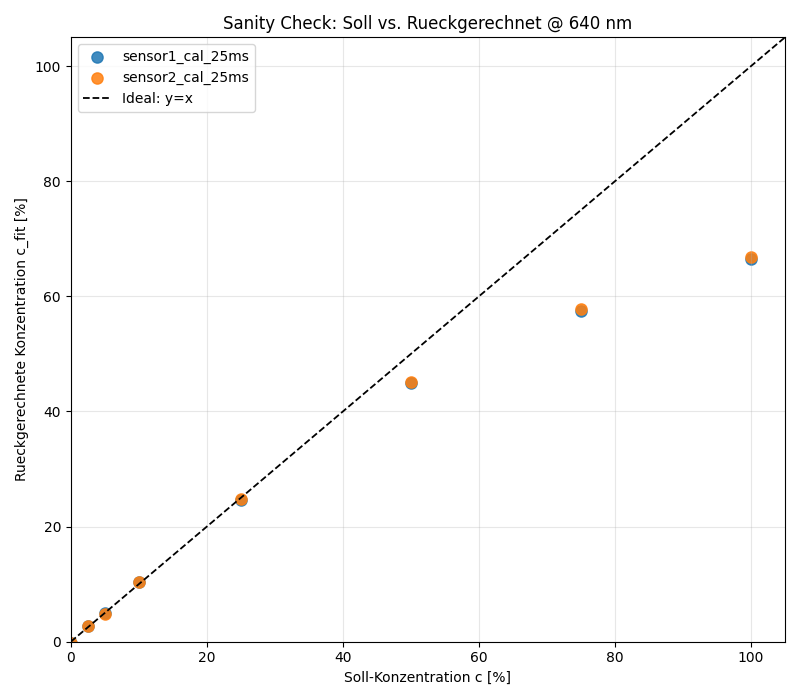

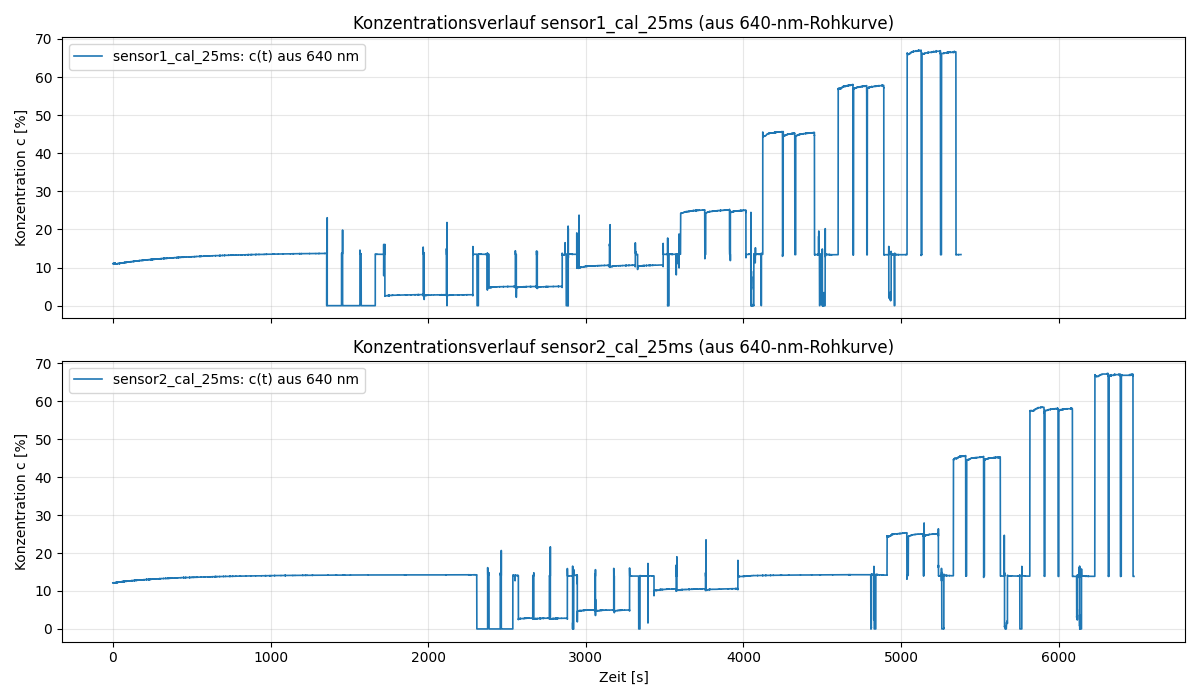


Konzentrationszeitreihe (Kurzstatistik, geclippt auf 0..100 %):
  sensor1_cal_25ms: n=71099, min=0.00 %, max=67.06 %, mean=18.26 %
  sensor2_cal_25ms: n=85043, min=0.00 %, max=67.34 %, mean=17.62 %


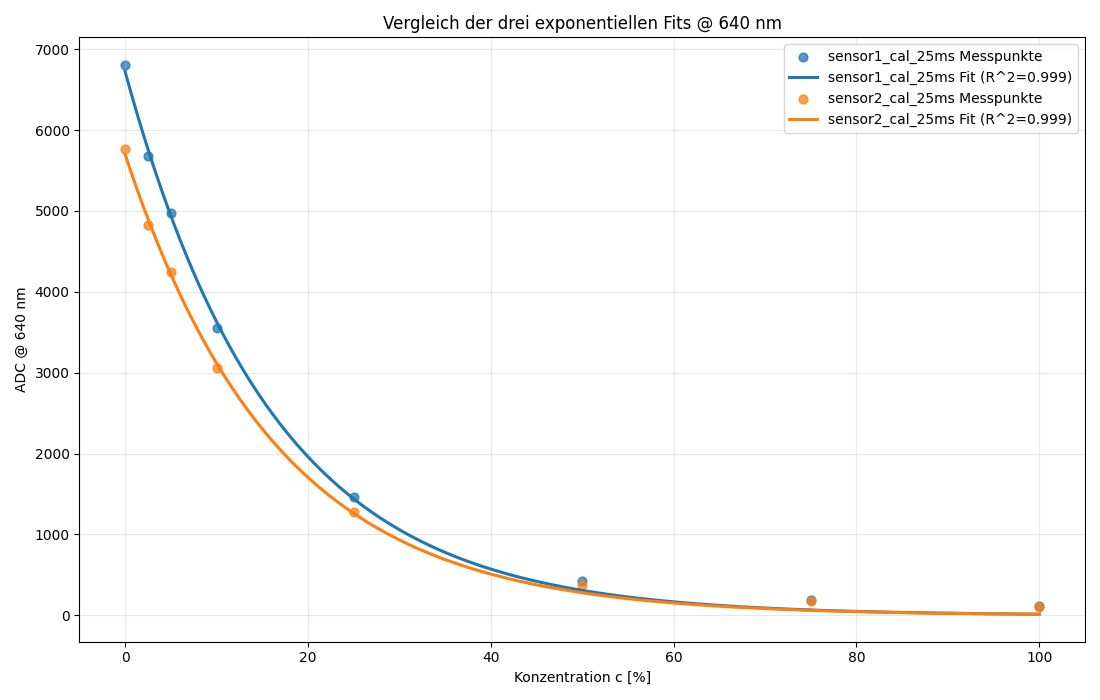

In [13]:
# Sanity Check fuer den aktuellen (ungewichteten) exponentiellen Fit
# Ziel: Kalibrierpunkte pruefen, Rueckrechnung auf Rohdaten zeigen,
# und alle drei Fits in einem Vergleich darstellen.

if 'fit_results' not in globals() or not fit_results:
    raise RuntimeError('Bitte zuerst die Fitting-Zelle ausfuehren.')
if 'group_stats_by_sensor' not in globals() or not group_stats_by_sensor:
    raise RuntimeError('Bitte zuerst die Statistik-Zelle ausfuehren.')
if 'sensor_keys' not in globals() or not sensor_keys:
    raise RuntimeError('sensor_keys sind nicht verfuegbar.')

if selected_wavelength != '640':
    print(f"Hinweis: selected_wavelength={selected_wavelength}. Sanity-Check ist fuer 640 nm vorgesehen.")

# --- Teil 1: Kalibrierpunkte rueckrechnen und Fehler je Marker prüfen ---
sanity_tables = {}

for sensor_key, fit_vals in fit_results.items():
    group_stats = group_stats_by_sensor.get(sensor_key)
    if group_stats is None or group_stats.empty:
        continue

    bl = group_stats[['marker_group', 'mean']].copy()
    bl = bl.rename(columns={'marker_group': 'marker', 'mean': 'mean_adc'})
    bl['concentration_pct'] = bl['marker'].apply(marker_to_concentration_pct)
    bl = bl[bl['mean_adc'] > 0].copy().sort_values('concentration_pct')
    if bl.empty:
        continue

    I0_fit = float(fit_vals['I0'])
    alpha_fit = float(fit_vals['alpha'])

    bl['c_backcalc_pct'] = -np.log(bl['mean_adc'] / I0_fit) / alpha_fit
    bl['c_error_pct'] = bl['c_backcalc_pct'] - bl['concentration_pct']
    bl['abs_error_pct'] = bl['c_error_pct'].abs()

    mae = float(bl['abs_error_pct'].mean())
    rmse = float(np.sqrt(np.mean(np.square(bl['c_error_pct']))))

    sanity_tables[sensor_key] = bl

    print(f"\n{sensor_key} -> MAE={mae:.2f} %, RMSE={rmse:.2f} %, max|err|={bl['abs_error_pct'].max():.2f} %")
    display(bl[['marker', 'concentration_pct', 'mean_adc', 'c_backcalc_pct', 'c_error_pct', 'abs_error_pct']])

if not sanity_tables:
    raise RuntimeError('Keine Sanity-Tabellen erzeugt.')

# Plot: Soll vs. Rueckgerechnet pro Sensor (Ideal: y=x)
fig, ax = plt.subplots(figsize=(8, 7))
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

for i, (sensor_key, tbl) in enumerate(sanity_tables.items()):
    color = colors[i % len(colors)]
    ax.scatter(tbl['concentration_pct'], tbl['c_backcalc_pct'], s=65, color=color, alpha=0.85, label=sensor_key)

diag_min = 0.0
diag_max = 105.0
ax.plot([diag_min, diag_max], [diag_min, diag_max], 'k--', lw=1.3, label='Ideal: y=x')
ax.set_xlim(diag_min, diag_max)
ax.set_ylim(diag_min, diag_max)
ax.set_xlabel('Soll-Konzentration c [%]')
ax.set_ylabel('Rueckgerechnete Konzentration c_fit [%]')
ax.set_title('Sanity Check: Soll vs. Rueckgerechnet @ 640 nm')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# --- Teil 2: Konzentrationsverlauf aus 640-nm-Rohdaten ---
concentration_timeseries = {}

for sensor_key in sensor_keys:
    if sensor_key not in fit_results:
        continue

    sensor_df = analyzer.datasets[sensor_key].copy()
    if 'device' in sensor_df.columns:
        sensor_df = sensor_df[sensor_df['device'] != 99].copy()

    if selected_wavelength not in sensor_df.columns:
        continue

    adc = pd.to_numeric(sensor_df[selected_wavelength], errors='coerce')
    ts = pd.to_numeric(sensor_df['timestamp'], errors='coerce')

    I0_fit = float(fit_results[sensor_key]['I0'])
    alpha_fit = float(fit_results[sensor_key]['alpha'])

    valid = adc.notna() & ts.notna() & (adc > 0) & (alpha_fit > 0)
    df_c = pd.DataFrame({'timestamp_s': ts[valid], 'adc_640': adc[valid]}).sort_values('timestamp_s')

    df_c['conc_pct_raw'] = -np.log(df_c['adc_640'] / I0_fit) / alpha_fit
    df_c['conc_pct'] = df_c['conc_pct_raw'].clip(lower=0, upper=100)

    concentration_timeseries[sensor_key] = df_c

fig, axes = plt.subplots(len(concentration_timeseries), 1, figsize=(12, 3.5 * len(concentration_timeseries)), sharex=True)
if len(concentration_timeseries) == 1:
    axes = [axes]

for ax, (sensor_key, df_c) in zip(axes, concentration_timeseries.items()):
    ax.plot(df_c['timestamp_s'], df_c['conc_pct'], lw=1.2, label=f'{sensor_key}: c(t) aus 640 nm')
    ax.set_ylabel('Konzentration c [%]')
    ax.set_title(f'Konzentrationsverlauf {sensor_key} (aus 640-nm-Rohkurve)')
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel('Zeit [s]')
plt.tight_layout()
plt.show()

print('\nKonzentrationszeitreihe (Kurzstatistik, geclippt auf 0..100 %):')
for sensor_key, df_c in concentration_timeseries.items():
    print(
        f"  {sensor_key}: n={len(df_c)}, "
        f"min={df_c['conc_pct'].min():.2f} %, "
        f"max={df_c['conc_pct'].max():.2f} %, "
        f"mean={df_c['conc_pct'].mean():.2f} %"
    )

# --- Teil 3: Alle drei Fits in einem Vergleichsplot ---
fig, ax = plt.subplots(figsize=(11, 7))
for i, (sensor_key, fit_vals) in enumerate(fit_results.items()):
    color = colors[i % len(colors)]
    tbl = sanity_tables.get(sensor_key)
    if tbl is None or tbl.empty:
        continue

    xfit = np.linspace(float(tbl['concentration_pct'].min()), float(tbl['concentration_pct'].max()), 300)
    yfit = intensity_model(xfit, float(fit_vals['I0']), float(fit_vals['alpha']))

    ax.scatter(tbl['concentration_pct'], tbl['mean_adc'], s=40, color=color, alpha=0.75, label=f"{sensor_key} Messpunkte")
    ax.plot(xfit, yfit, color=color, lw=2.2, label=f"{sensor_key} Fit (R^2={fit_vals['r2']:.3f})")

ax.set_xlabel('Konzentration c [%]')
ax.set_ylabel('ADC @ 640 nm')
ax.set_title('Vergleich der drei exponentiellen Fits @ 640 nm')
ax.grid(True, alpha=0.3)
ax.legend(ncol=1)
plt.tight_layout()
plt.show()

# Fit Optimization



sensor1_cal_25ms -> Optimierter Fit
  Funktion: I(c) = 6328.0718 * exp(-0.046004 * c)
  R^2(ADC)=0.9850, RMSE(c)=6.013 %, MAE low/mid/high=1.14/7.86/6.48 %


,marker,concentration_pct,mean_adc,c_backcalc_pct,c_error_pct
0,H20,0.0,6807.267462,-1.586725,-1.586725
1,C002,2.5,5678.235632,2.355355,-0.144645
2,C005,5.0,4970.298408,5.249921,0.249921
3,C010,10.0,3550.678603,12.561099,2.561099
4,C025,25.0,1467.780283,31.763637,6.763637
5,C050,50.0,419.967286,58.964279,8.964279
6,C075,75.0,195.668877,75.566275,0.566275
7,C100,100.0,112.470822,87.602920,-12.397080


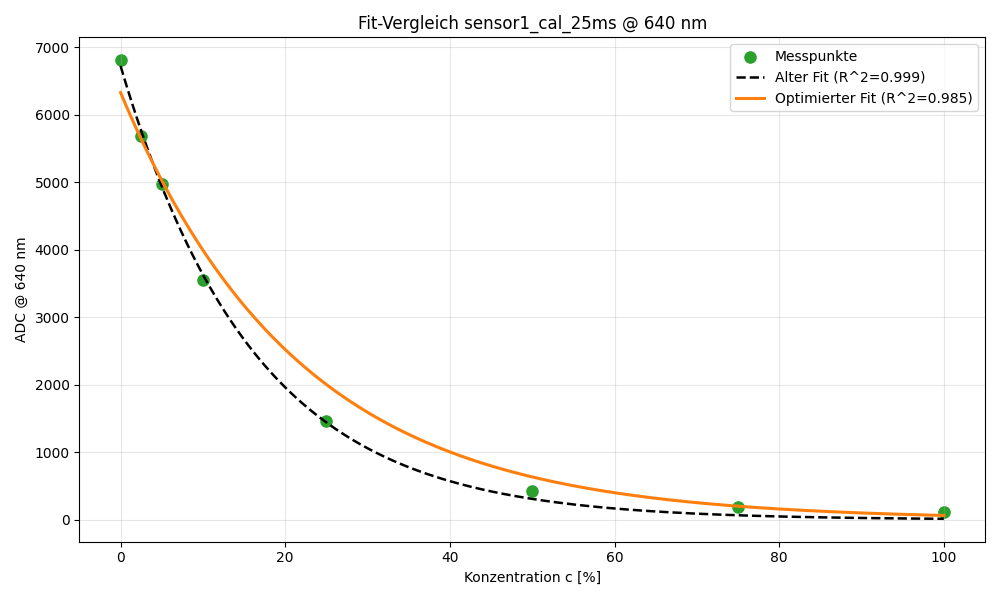


sensor2_cal_25ms -> Optimierter Fit
  Funktion: I(c) = 5374.1264 * exp(-0.045328 * c)
  R^2(ADC)=0.9854, RMSE(c)=5.917 %, MAE low/mid/high=1.09/7.72/6.48 %


,marker,concentration_pct,mean_adc,c_backcalc_pct,c_error_pct
0,H20,0.0,5772.126391,-1.576184,-1.576184
1,C002,2.5,4826.331998,2.371832,-0.128168
2,C005,5.0,4245.167334,5.202465,0.202465
3,C010,10.0,3053.351580,12.472693,2.472693
4,C025,25.0,1272.135291,31.788623,6.788623
5,C050,50.0,376.431687,58.653443,8.653443
6,C075,75.0,173.686693,75.717771,0.717771
7,C100,100.0,100.655541,87.753482,-12.246518


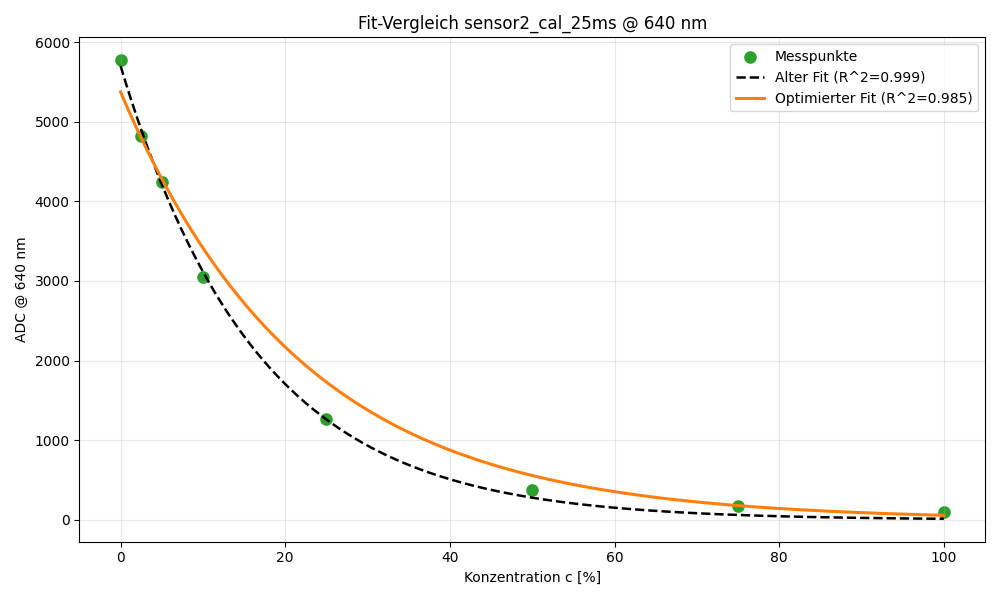

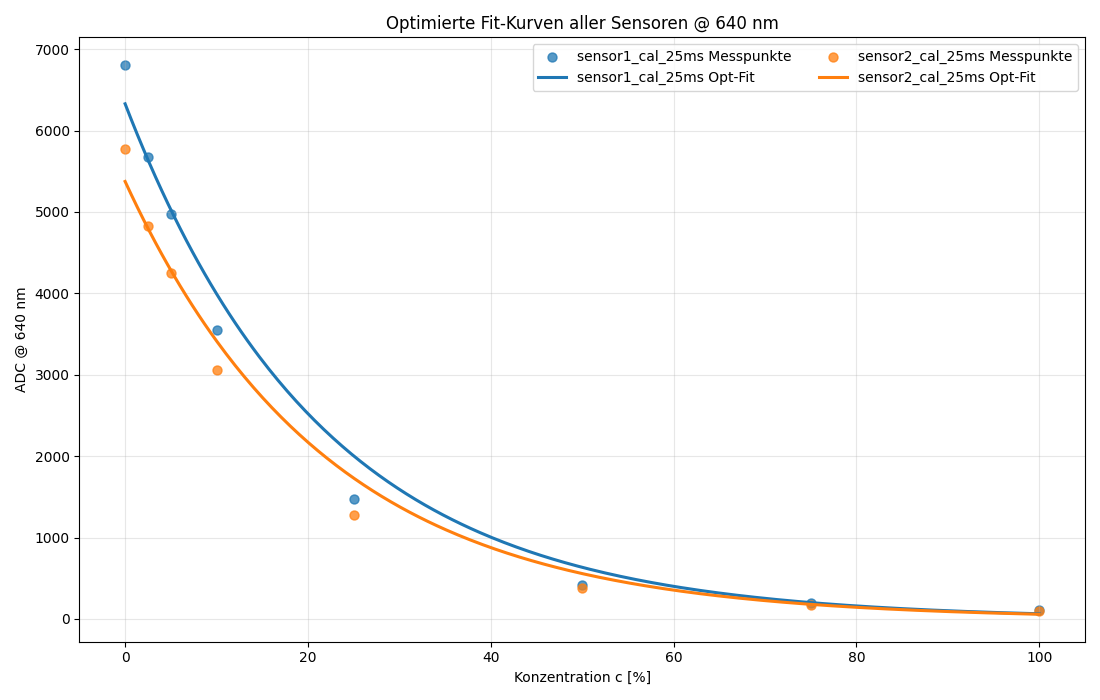


Optimierte Fit-Funktionen:
  sensor1_cal_25ms: I(c) = 6328.0718 * exp(-0.046004 * c) | R^2=0.9850, RMSE(c)=6.013 %, MAE low/mid/high=1.14/7.86/6.48 %
  sensor2_cal_25ms: I(c) = 5374.1264 * exp(-0.045328 * c) | R^2=0.9854, RMSE(c)=5.917 %, MAE low/mid/high=1.09/7.72/6.48 %


In [14]:
# Optimierter Kompromiss-Fit fuer alle Konzentrationsbereiche
# Dieser Block laesst den bisherigen Fit unveraendert und berechnet zusaetzlich
# einen robusten Multi-Objective-Fit pro Sensor.

from scipy.optimize import least_squares

if 'group_stats_by_sensor' not in globals() or not group_stats_by_sensor:
    raise RuntimeError('Bitte zuerst die Statistik-Zelle ausfuehren.')

# Falls die Funktionen nicht mehr im Scope sind, hier absichern.
if 'marker_to_concentration_pct' not in globals():
    def marker_to_concentration_pct(marker: str) -> float:
        mk = str(marker).strip().upper()
        if mk in {'H20', 'H2O'}:
            return 0.0
        if mk == 'C002':
            return 2.5
        mm = re.match(r'^C(\d+)$', mk)
        if mm:
            return float(int(mm.group(1)))
        raise ValueError(f'Unbekannter Marker: {marker}')

if 'intensity_model' not in globals():
    def intensity_model(c, I0, alpha):
        return I0 * np.exp(-alpha * c)

fit_results_optimized = {}

# Tuning-Parameter fuer den Kompromiss-Fit
lambda_adc = 1.0
lambda_c = 1.15
robust_loss = 'soft_l1'

for sensor_key, group_stats in group_stats_by_sensor.items():
    bl = group_stats[['marker_group', 'mean']].copy()
    bl = bl.rename(columns={'marker_group': 'marker', 'mean': 'mean_adc'})
    bl['concentration_pct'] = bl['marker'].apply(marker_to_concentration_pct)
    bl = bl[bl['mean_adc'] > 0].copy().sort_values('concentration_pct')

    if len(bl) < 3:
        print(f"{sensor_key}: Zu wenige Punkte fuer optimierten Fit.")
        continue

    c_data = bl['concentration_pct'].to_numpy(dtype=float)
    I_data = bl['mean_adc'].to_numpy(dtype=float)

    # Gewichte: unten und oben leicht staerker, Mitte neutral.
    w = np.ones_like(c_data, dtype=float)
    w[c_data <= 10.0] *= 1.25
    w[c_data >= 75.0] *= 1.25

    # Skalierungen fuer dimensionslose Residuen.
    scale_I = max(float(np.ptp(I_data)), 1.0)
    scale_c = max(float(np.ptp(c_data)), 1.0)

    # Startwert vom bisherigen Fit nutzen, falls verfuegbar.
    if 'fit_results' in globals() and sensor_key in fit_results:
        x0 = np.array([
            float(fit_results[sensor_key]['I0']),
            float(fit_results[sensor_key]['alpha']),
        ], dtype=float)
    else:
        x0 = np.array([float(np.max(I_data)), 0.05], dtype=float)

    def residuals(theta):
        I0, alpha = float(theta[0]), float(theta[1])
        I_model = intensity_model(c_data, I0, alpha)

        # ADC-Raum
        r_adc = (I_model - I_data) / scale_I

        # Konzentrations-Raum via Rueckrechnung
        ratio = np.clip(I_data / I0, 1e-12, None)
        c_back = -np.log(ratio) / max(alpha, 1e-12)
        r_c = (c_back - c_data) / scale_c

        r1 = np.sqrt(lambda_adc * w) * r_adc
        r2 = np.sqrt(lambda_c * w) * r_c
        return np.concatenate([r1, r2])

    res = least_squares(
        residuals,
        x0=x0,
        bounds=([1e-9, 1e-8], [np.inf, 5.0]),
        loss=robust_loss,
        f_scale=1.0,
        max_nfev=50000,
    )

    I0_opt, alpha_opt = float(res.x[0]), float(res.x[1])

    I_fitted = intensity_model(c_data, I0_opt, alpha_opt)
    sst = float(np.sum((I_data - np.mean(I_data)) ** 2))
    ssr = float(np.sum((I_data - I_fitted) ** 2))
    r2_adc = np.nan if sst == 0 else 1.0 - (ssr / sst)

    c_back = -np.log(np.clip(I_data / I0_opt, 1e-12, None)) / alpha_opt
    c_err = c_back - c_data
    rmse_c = float(np.sqrt(np.mean(np.square(c_err))))

    low_mask = c_data <= 10.0
    mid_mask = (c_data > 10.0) & (c_data < 75.0)
    high_mask = c_data >= 75.0

    def mae_for(mask):
        if np.any(mask):
            return float(np.mean(np.abs(c_err[mask])))
        return np.nan

    mae_low = mae_for(low_mask)
    mae_mid = mae_for(mid_mask)
    mae_high = mae_for(high_mask)

    fit_results_optimized[sensor_key] = {
        'I0': I0_opt,
        'alpha': alpha_opt,
        'r2_adc': r2_adc,
        'rmse_c': rmse_c,
        'mae_low': mae_low,
        'mae_mid': mae_mid,
        'mae_high': mae_high,
        'fit_function': f"I(c) = {I0_opt:.4f} * exp(-{alpha_opt:.6f} * c)",
    }

    check = bl.copy()
    check['c_backcalc_pct'] = c_back
    check['c_error_pct'] = c_err

    print(f"\n{sensor_key} -> Optimierter Fit")
    print(f"  Funktion: I(c) = {I0_opt:.4f} * exp(-{alpha_opt:.6f} * c)")
    print(f"  R^2(ADC)={r2_adc:.4f}, RMSE(c)={rmse_c:.3f} %, MAE low/mid/high={mae_low:.2f}/{mae_mid:.2f}/{mae_high:.2f} %")
    display(check[['marker', 'concentration_pct', 'mean_adc', 'c_backcalc_pct', 'c_error_pct']])

    # Plot pro Sensor: alter Fit vs optimierter Fit
    xfit = np.linspace(float(np.min(c_data)), float(np.max(c_data)), 300)
    yfit_opt = intensity_model(xfit, I0_opt, alpha_opt)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(c_data, I_data, s=65, color='tab:green', label='Messpunkte')

    if 'fit_results' in globals() and sensor_key in fit_results:
        I0_old = float(fit_results[sensor_key]['I0'])
        alpha_old = float(fit_results[sensor_key]['alpha'])
        yfit_old = intensity_model(xfit, I0_old, alpha_old)
        ax.plot(xfit, yfit_old, 'k--', lw=1.8, label=f"Alter Fit (R^2={fit_results[sensor_key]['r2']:.3f})")

    ax.plot(xfit, yfit_opt, color='tab:orange', lw=2.2, label=f"Optimierter Fit (R^2={r2_adc:.3f})")
    ax.set_xlabel('Konzentration c [%]')
    ax.set_ylabel('ADC @ 640 nm')
    ax.set_title(f'Fit-Vergleich {sensor_key} @ {selected_wavelength} nm')
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

if not fit_results_optimized:
    raise RuntimeError('Kein optimierter Fit berechnet.')

# Gesamtdarstellung: optimierte Fits aller Sensoren in einem Plot
fig, ax = plt.subplots(figsize=(11, 7))
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

for i, (sensor_key, vals) in enumerate(fit_results_optimized.items()):
    color = colors[i % len(colors)]
    group_stats = group_stats_by_sensor[sensor_key]

    bl = group_stats[['marker_group', 'mean']].copy()
    bl = bl.rename(columns={'marker_group': 'marker', 'mean': 'mean_adc'})
    bl['concentration_pct'] = bl['marker'].apply(marker_to_concentration_pct)
    bl = bl[bl['mean_adc'] > 0].copy().sort_values('concentration_pct')

    c_data = bl['concentration_pct'].to_numpy(dtype=float)
    I_data = bl['mean_adc'].to_numpy(dtype=float)

    xfit = np.linspace(float(np.min(c_data)), float(np.max(c_data)), 300)
    yfit = intensity_model(xfit, float(vals['I0']), float(vals['alpha']))

    ax.scatter(c_data, I_data, s=42, color=color, alpha=0.75, label=f"{sensor_key} Messpunkte")
    ax.plot(xfit, yfit, color=color, lw=2.2, label=f"{sensor_key} Opt-Fit")

ax.set_xlabel('Konzentration c [%]')
ax.set_ylabel('ADC @ 640 nm')
ax.set_title('Optimierte Fit-Kurven aller Sensoren @ 640 nm')
ax.grid(True, alpha=0.3)
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

print('\nOptimierte Fit-Funktionen:')
for sensor_key, vals in fit_results_optimized.items():
    print(
        f"  {sensor_key}: {vals['fit_function']} | "
        f"R^2={vals['r2_adc']:.4f}, RMSE(c)={vals['rmse_c']:.3f} %, "
        f"MAE low/mid/high={vals['mae_low']:.2f}/{vals['mae_mid']:.2f}/{vals['mae_high']:.2f} %"
    )


sensor1_cal_25ms -> Polyfit Grad 3 (c aus log(I))
  RMSE(c)=0.397 %, MAE=0.336 %, MAE low/mid/high=0.37/0.45/0.15 %


,marker,concentration_pct,mean_adc,c_backcalc_poly_pct,c_error_poly_pct
0,H20,0.0,6807.267462,-0.522146,-0.522146
1,C002,2.5,5678.235632,2.794955,0.294955
2,C005,5.0,4970.298408,5.103250,0.103250
3,C010,10.0,3550.678603,10.578594,0.578594
4,C025,25.0,1467.780283,24.313056,-0.686944
5,C050,50.0,419.967286,50.207999,0.207999
6,C075,75.0,195.668877,75.158341,0.158341
7,C100,100.0,112.470822,99.865953,-0.134047



sensor2_cal_25ms -> Polyfit Grad 3 (c aus log(I))
  RMSE(c)=0.372 %, MAE=0.317 %, MAE low/mid/high=0.35/0.28/0.29 %


,marker,concentration_pct,mean_adc,c_backcalc_poly_pct,c_error_poly_pct
0,H20,0.0,5772.126391,-0.500116,-0.500116
1,C002,2.5,4826.331998,2.808816,0.308816
2,C005,5.0,4245.167334,5.063972,0.063972
3,C010,10.0,3053.351580,10.525363,0.525363
4,C025,25.0,1272.135291,24.450659,-0.549341
5,C050,50.0,376.431687,49.991991,-0.008009
6,C075,75.0,173.686693,75.370070,0.370070
7,C100,100.0,100.655541,99.789244,-0.210756


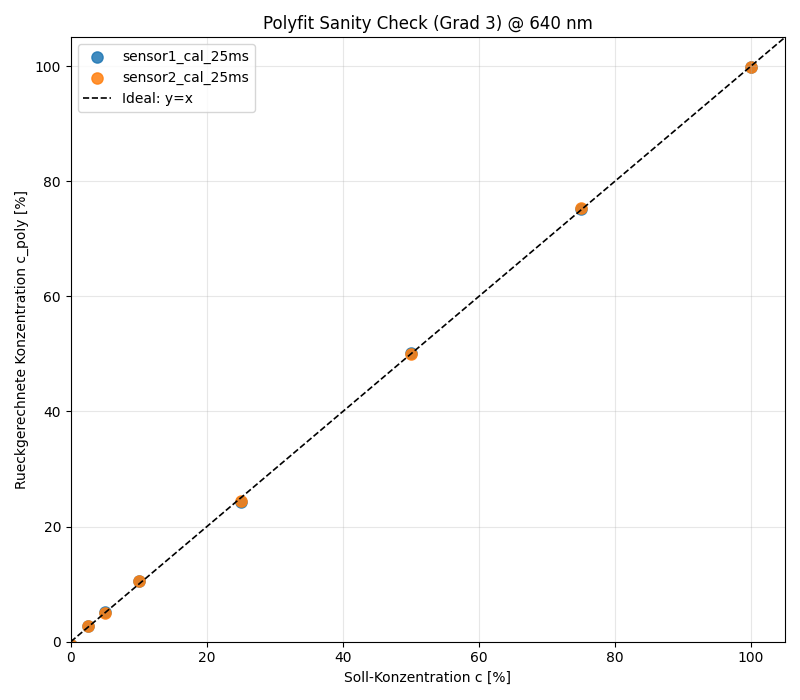

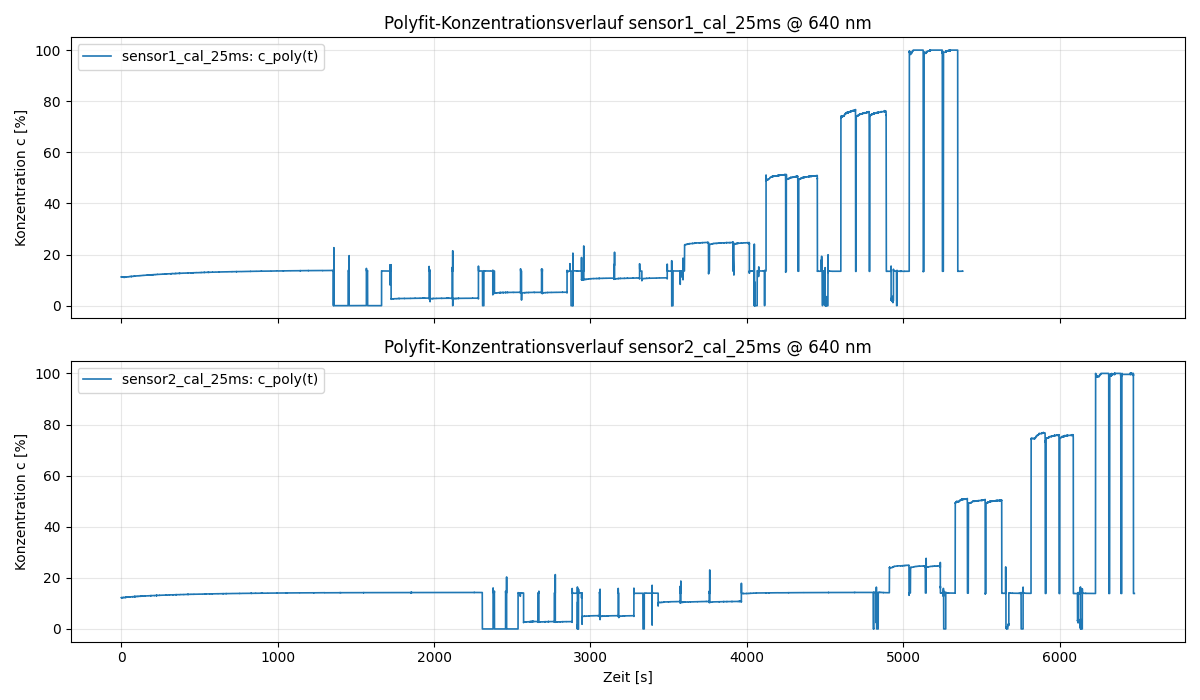


Polyfit-Koeffizienten (c = p(log(I))):
  sensor1_cal_25ms: [-1.218375e+00, 2.861390e+01, -2.392787e+02, 7.200428e+02]
  sensor2_cal_25ms: [-1.228479e+00, 2.834690e+01, -2.336613e+02, 6.949799e+02]


In [15]:
# Polyfit-Test (separat): c = p(log(I))
# Ziel: Rueckrechnung ueber den gesamten Konzentrationsbereich verbessern,
# ohne den alten exponentiellen Fit zu ersetzen.

if 'group_stats_by_sensor' not in globals() or not group_stats_by_sensor:
    raise RuntimeError('Bitte zuerst die Statistik-Zelle ausfuehren.')

if 'marker_to_concentration_pct' not in globals():
    def marker_to_concentration_pct(marker: str) -> float:
        mk = str(marker).strip().upper()
        if mk in {'H20', 'H2O'}:
            return 0.0
        if mk == 'C002':
            return 2.5
        mm = re.match(r'^C(\d+)$', mk)
        if mm:
            return float(int(mm.group(1)))
        raise ValueError(f'Unbekannter Marker: {marker}')

poly_degree = 3
polyfit_results = {}

for sensor_key, group_stats in group_stats_by_sensor.items():
    bl = group_stats[['marker_group', 'mean']].copy()
    bl = bl.rename(columns={'marker_group': 'marker', 'mean': 'mean_adc'})
    bl['concentration_pct'] = bl['marker'].apply(marker_to_concentration_pct)
    bl = bl[bl['mean_adc'] > 0].copy().sort_values('concentration_pct')

    if len(bl) < poly_degree + 1:
        print(f"{sensor_key}: Zu wenige Punkte fuer Polyfit Grad {poly_degree}.")
        continue

    c_data = bl['concentration_pct'].to_numpy(dtype=float)
    I_data = bl['mean_adc'].to_numpy(dtype=float)
    x_logI = np.log(I_data)

    # Rueckrechnungsmodell: c(I) als Polynom in log(I)
    coeff = np.polyfit(x_logI, c_data, deg=poly_degree)
    c_back = np.polyval(coeff, x_logI)
    c_err = c_back - c_data

    rmse_c = float(np.sqrt(np.mean(np.square(c_err))))
    mae_c = float(np.mean(np.abs(c_err)))

    low_mask = c_data <= 10.0
    mid_mask = (c_data > 10.0) & (c_data < 75.0)
    high_mask = c_data >= 75.0

    def mae_for(mask):
        return float(np.mean(np.abs(c_err[mask]))) if np.any(mask) else np.nan

    mae_low = mae_for(low_mask)
    mae_mid = mae_for(mid_mask)
    mae_high = mae_for(high_mask)

    polyfit_results[sensor_key] = {
        'coeff': coeff,
        'degree': poly_degree,
        'rmse_c': rmse_c,
        'mae_c': mae_c,
        'mae_low': mae_low,
        'mae_mid': mae_mid,
        'mae_high': mae_high,
    }

    check = bl.copy()
    check['c_backcalc_poly_pct'] = c_back
    check['c_error_poly_pct'] = c_err

    print(f"\n{sensor_key} -> Polyfit Grad {poly_degree} (c aus log(I))")
    print(f"  RMSE(c)={rmse_c:.3f} %, MAE={mae_c:.3f} %, MAE low/mid/high={mae_low:.2f}/{mae_mid:.2f}/{mae_high:.2f} %")
    display(check[['marker', 'concentration_pct', 'mean_adc', 'c_backcalc_poly_pct', 'c_error_poly_pct']])

# Vergleichsplot: Soll vs Rueckgerechnet (Polyfit)
fig, ax = plt.subplots(figsize=(8, 7))
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

for i, (sensor_key, vals) in enumerate(polyfit_results.items()):
    color = colors[i % len(colors)]
    group_stats = group_stats_by_sensor[sensor_key]

    bl = group_stats[['marker_group', 'mean']].copy()
    bl = bl.rename(columns={'marker_group': 'marker', 'mean': 'mean_adc'})
    bl['concentration_pct'] = bl['marker'].apply(marker_to_concentration_pct)
    bl = bl[bl['mean_adc'] > 0].copy().sort_values('concentration_pct')

    c_data = bl['concentration_pct'].to_numpy(dtype=float)
    c_back = np.polyval(vals['coeff'], np.log(bl['mean_adc'].to_numpy(dtype=float)))

    ax.scatter(c_data, c_back, s=65, color=color, alpha=0.85, label=f"{sensor_key}")

diag = np.linspace(0, 105, 200)
ax.plot(diag, diag, 'k--', lw=1.2, label='Ideal: y=x')
ax.set_xlim(0, 105)
ax.set_ylim(0, 105)
ax.set_xlabel('Soll-Konzentration c [%]')
ax.set_ylabel('Rueckgerechnete Konzentration c_poly [%]')
ax.set_title(f'Polyfit Sanity Check (Grad {poly_degree}) @ 640 nm')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Anwendung auf Rohkurven @ 640 nm
if 'sensor_keys' in globals() and sensor_keys:
    fig, axes = plt.subplots(len(polyfit_results), 1, figsize=(12, 3.5 * len(polyfit_results)), sharex=True)
    if len(polyfit_results) == 1:
        axes = [axes]

    for ax, (sensor_key, vals) in zip(axes, polyfit_results.items()):
        sensor_df = analyzer.datasets[sensor_key].copy()
        if 'device' in sensor_df.columns:
            sensor_df = sensor_df[sensor_df['device'] != 99].copy()

        adc = pd.to_numeric(sensor_df[selected_wavelength], errors='coerce')
        ts = pd.to_numeric(sensor_df['timestamp'], errors='coerce')
        valid = adc.notna() & ts.notna() & (adc > 0)

        c_poly = np.polyval(vals['coeff'], np.log(adc[valid].to_numpy(dtype=float)))
        c_poly = np.clip(c_poly, 0, 100)

        ax.plot(ts[valid], c_poly, lw=1.2, label=f'{sensor_key}: c_poly(t)')
        ax.set_ylabel('Konzentration c [%]')
        ax.set_title(f'Polyfit-Konzentrationsverlauf {sensor_key} @ {selected_wavelength} nm')
        ax.grid(True, alpha=0.3)
        ax.legend()

    axes[-1].set_xlabel('Zeit [s]')
    plt.tight_layout()
    plt.show()

print('\nPolyfit-Koeffizienten (c = p(log(I))):')
for sensor_key, vals in polyfit_results.items():
    coeff_txt = ', '.join([f'{v:.6e}' for v in vals['coeff']])
    print(f"  {sensor_key}: [{coeff_txt}]")

# Abschluss: Fit-Zusammenfassung

In diesem Abschnitt werden die beiden Modelle pro Sensor als anwendbare Kalibrierfunktionen zusammengefasst:

- Exponentialfit (physikalisch motiviert):
  - $I(c) = I_0 \cdot e^{-\alpha c}$
- Polyfit-Variante (datengetrieben):
  - Rueckrechnung: $c = p(\log I)$
  - Vorwaertsdarstellung als $I(c)$ erfolgt hier numerisch invertiert aus $c = p(\log I)$,
    damit die ADC-ueber-c-Kurve ohne unphysikalisches Ueberschwingen geplottet wird.

## Polyfit als Rueckrechnungsfunktion c(I) mit eingesetzten Koeffizienten

Allgemeine Form (Grad 3):

$$
c(I) = b_3 \,(\ln I)^3 + b_2 \,(\ln I)^2 + b_1\,\ln I + b_0
$$

Konkrete Funktionen pro Sensor:

- sensor0_cal_25ms:

$$
c(I) = -1.010165\,(\ln I)^3 + 2.352064\cdot 10^1\,(\ln I)^2 - 1.975172\cdot 10^2\,\ln I + 6.033126\cdot 10^2
$$

- sensor1_cal_25ms:

$$
c(I) = -1.218375\,(\ln I)^3 + 2.861390\cdot 10^1\,(\ln I)^2 - 2.392787\cdot 10^2\,\ln I + 7.200428\cdot 10^2
$$

- sensor2_cal_25ms:

$$
c(I) = -1.340884\,(\ln I)^3 + 3.047501\cdot 10^1\,(\ln I)^2 - 2.467817\cdot 10^2\,\ln I + 7.213360\cdot 10^2
$$

## Polyfit als Vorwaertsfunktion I(c) mit eingesetzten Koeffizienten

Allgemeine Form (Grad 3):

$$
I(c) = a_3 c^3 + a_2 c^2 + a_1 c + a_0
$$

Konkrete Funktionen pro Sensor:

- sensor0_cal_25ms:

$$
I(c) = -2.246340\cdot 10^{-2} c^3 + 4.509994\,c^2 - 2.846771\cdot 10^2 c + 5.853171\cdot 10^3
$$

- sensor1_cal_25ms:

$$
I(c) = -2.397383\cdot 10^{-2} c^3 + 4.845831\,c^2 - 3.093063\cdot 10^2 c + 6.491612\cdot 10^3
$$

- sensor2_cal_25ms:

$$
I(c) = -1.731262\cdot 10^{-2} c^3 + 3.593053\,c^2 - 2.385181\cdot 10^2 c + 5.297248\cdot 10^3
$$

Damit liegen beide Varianten als Funktion $I(c)$ vor und koennen auf die Sensordaten angewendet bzw. gegeneinander verglichen werden.

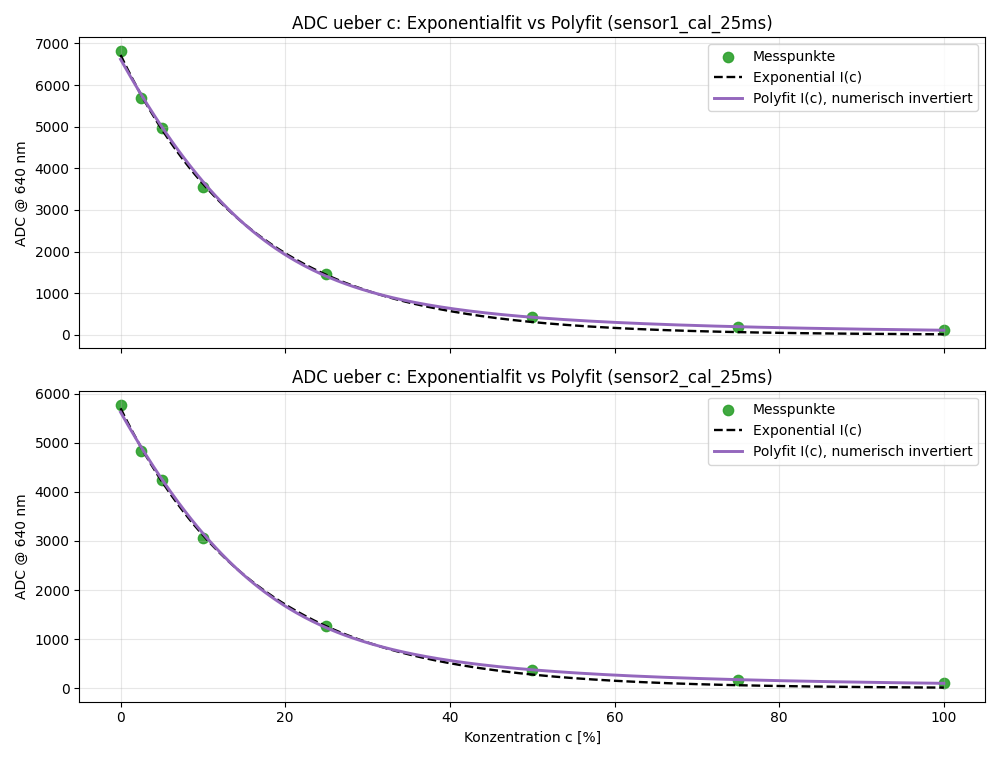

## Ergebniszusammenfassung der beiden Fits als I(c)

Die folgenden Kalibrierfunktionen koennen auf die Sensordaten angewendet werden:

- **sensor1_cal_25ms**
  - Exponentialfit: $I(c) = 6723.7152 * exp(-0.061603 * c)$
  - Polyfit: $c(I) = poly3(log(I)), coeff=[-1.218375e+00, 2.861390e+01, -2.392787e+02, 7.200428e+02] ; I(c) numerisch invertiert$

- **sensor2_cal_25ms**
  - Exponentialfit: $I(c) = 5701.0885 * exp(-0.060345 * c)$
  - Polyfit: $c(I) = poly3(log(I)), coeff=[-1.228479e+00, 2.834690e+01, -2.336613e+02, 6.949799e+02] ; I(c) numerisch invertiert$


In [16]:
# Abschluss-Ausgabe: Funktionen beider Fits + Polyfit-Plot als ADC ueber c

from IPython.display import Markdown, display

if 'fit_results' not in globals() or not fit_results:
    raise RuntimeError('fit_results fehlt. Bitte Exponential-Fit-Zelle ausfuehren.')
if 'polyfit_results' not in globals() or not polyfit_results:
    raise RuntimeError('polyfit_results fehlt. Bitte Polyfit-Zelle ausfuehren.')
if 'group_stats_by_sensor' not in globals() or not group_stats_by_sensor:
    raise RuntimeError('group_stats_by_sensor fehlt. Bitte Statistik-Zelle ausfuehren.')

summary_rows = []

fig, axes = plt.subplots(len(polyfit_results), 1, figsize=(10, 3.8 * len(polyfit_results)), sharex=True)
if len(polyfit_results) == 1:
    axes = [axes]

for ax, (sensor_key, pvals) in zip(axes, polyfit_results.items()):
    group_stats = group_stats_by_sensor[sensor_key]

    bl = group_stats[['marker_group', 'mean']].copy()
    bl = bl.rename(columns={'marker_group': 'marker', 'mean': 'mean_adc'})
    bl['concentration_pct'] = bl['marker'].apply(marker_to_concentration_pct)
    bl = bl[bl['mean_adc'] > 0].copy().sort_values('concentration_pct')

    c_data = bl['concentration_pct'].to_numpy(dtype=float)
    I_data = bl['mean_adc'].to_numpy(dtype=float)

    # Exponential I(c)
    exp_I0 = float(fit_results[sensor_key]['I0'])
    exp_alpha = float(fit_results[sensor_key]['alpha'])

    # Polyfit liegt als c = p(log(I)) vor. Fuer ADC-ueber-c wird numerisch invertiert.
    coeff_c_of_logI = np.asarray(pvals['coeff'], dtype=float)

    xfit = np.linspace(float(np.min(c_data)), float(np.max(c_data)), 400)
    y_exp = intensity_model(xfit, exp_I0, exp_alpha)

    I_min = max(float(np.min(I_data)) * 0.8, 1e-9)
    I_max = float(np.max(I_data)) * 1.1
    I_grid = np.linspace(I_min, I_max, 6000)
    c_grid = np.polyval(coeff_c_of_logI, np.log(I_grid))

    order = np.argsort(c_grid)
    c_sorted = c_grid[order]
    I_sorted = I_grid[order]

    c_unique, unique_idx = np.unique(c_sorted, return_index=True)
    I_unique = I_sorted[unique_idx]

    c_low = float(np.min(c_data))
    c_high = float(np.max(c_data))
    domain_mask = (c_unique >= c_low) & (c_unique <= c_high)

    if np.sum(domain_mask) >= 2:
        c_domain = c_unique[domain_mask]
        I_domain = I_unique[domain_mask]
        y_poly_inv = np.interp(xfit, c_domain, I_domain)
    else:
        y_poly_inv = np.full_like(xfit, np.nan)

    ax.scatter(c_data, I_data, s=55, color='tab:green', alpha=0.9, label='Messpunkte')
    ax.plot(xfit, y_exp, 'k--', lw=1.7, label='Exponential I(c)')
    ax.plot(xfit, y_poly_inv, color='tab:purple', lw=2.1, label='Polyfit I(c), numerisch invertiert')
    ax.set_ylabel('ADC @ 640 nm')
    ax.set_title(f'ADC ueber c: Exponentialfit vs Polyfit ({sensor_key})')
    ax.grid(True, alpha=0.3)
    ax.legend()

    coeff_txt = ', '.join([f'{v:.6e}' for v in coeff_c_of_logI])
    summary_rows.append({
        'sensor': sensor_key,
        'exp_func': f"I(c) = {exp_I0:.4f} * exp(-{exp_alpha:.6f} * c)",
        'poly_func': f"c(I) = poly3(log(I)), coeff=[{coeff_txt}] ; I(c) numerisch invertiert",
    })

axes[-1].set_xlabel('Konzentration c [%]')
plt.tight_layout()
plt.show()

# Markdown-Zusammenfassung erzeugen
md_lines = [
    '## Ergebniszusammenfassung der beiden Fits als I(c)',
    '',
    'Die folgenden Kalibrierfunktionen koennen auf die Sensordaten angewendet werden:',
    '',
]

for row in summary_rows:
    md_lines.append(f"- **{row['sensor']}**")
    md_lines.append(f"  - Exponentialfit: ${row['exp_func']}$")
    md_lines.append(f"  - Polyfit: ${row['poly_func']}$")
    md_lines.append('')

display(Markdown('\n'.join(md_lines)))


sensor1_cal_25ms -> Offset-Exponentialfit (mit Schranke fuer I_inf)
  I(c) = 94.8355 + (6633.1044 - 94.8355) * exp(-0.058805 * c)
  R^2(ADC)=0.9984, RMSE(c, geclippt 0..100)=1.606 %
  C100 Rueckrechnung alt/offset: 66.40 / 100.00 %


,marker,concentration_pct,mean_adc,c_back_old_pct,c_err_old_pct,c_back_offset_raw_pct,c_back_offset_pct,c_err_offset_pct
0,H20,0.0,6807.267462,0.000000,0.000000,-0.447050,0.000000,0.000000
1,C002,2.5,5678.235632,2.743388,0.243388,2.684697,2.684697,0.184697
2,C005,5.0,4970.298408,4.904989,-0.095011,4.990319,4.990319,-0.009681
3,C010,10.0,3550.678603,10.364826,0.364826,10.842656,10.842656,0.842656
4,C025,25.0,1467.780283,24.704885,-0.295115,26.540358,26.540358,1.540358
5,C050,50.0,419.967286,45.017763,-4.982237,51.036141,51.036141,1.036141
6,C075,75.0,195.668877,57.415791,-17.584209,70.945242,70.945242,-4.054758
7,C100,100.0,112.470822,66.404508,-33.595492,100.595034,100.000000,0.000000


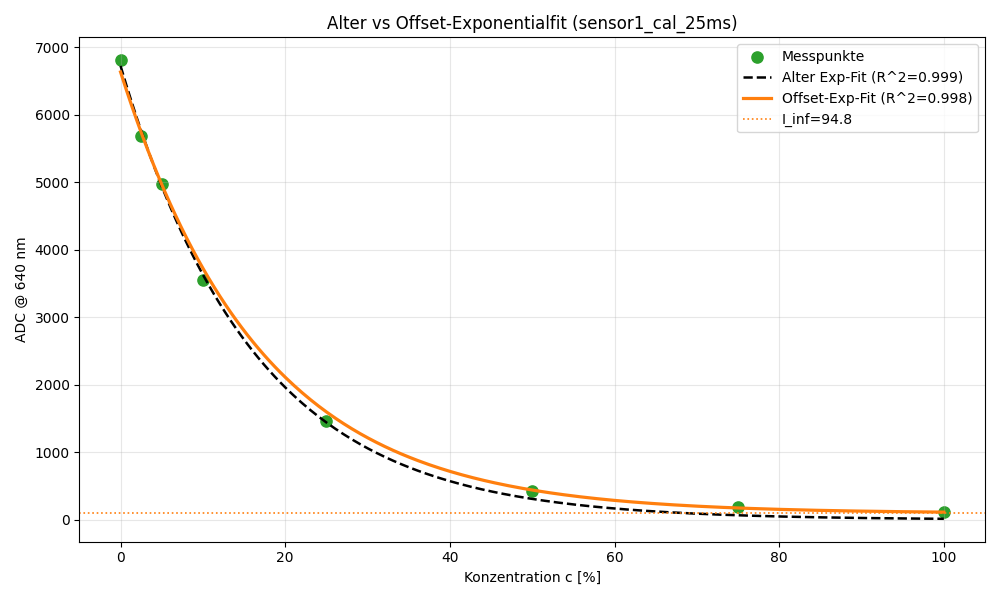


sensor2_cal_25ms -> Offset-Exponentialfit (mit Schranke fuer I_inf)
  I(c) = 84.3675 + (5630.6824 - 84.3675) * exp(-0.057966 * c)
  R^2(ADC)=0.9985, RMSE(c, geclippt 0..100)=1.501 %
  C100 Rueckrechnung alt/offset: 66.89 / 100.00 %


,marker,concentration_pct,mean_adc,c_back_old_pct,c_err_old_pct,c_back_offset_raw_pct,c_back_offset_pct,c_err_offset_pct
0,H20,0.0,5772.126391,0.000000,0.000000,-0.434436,0.000000,0.000000
1,C002,2.5,4826.331998,2.760292,0.260292,2.702997,2.702997,0.202997
2,C005,5.0,4245.167334,4.886485,-0.113515,4.958525,4.958525,-0.041475
3,C010,10.0,3053.351580,10.347423,0.347423,10.780677,10.780677,0.780677
4,C025,25.0,1272.135291,24.856335,-0.143665,26.585500,26.585500,1.585500
5,C050,50.0,376.431687,45.035498,-4.964502,50.786838,50.786838,0.786838
6,C075,75.0,173.686693,57.853148,-17.146852,71.225628,71.225628,-3.774372
7,C100,100.0,100.655541,66.893617,-33.106383,100.583899,100.000000,0.000000


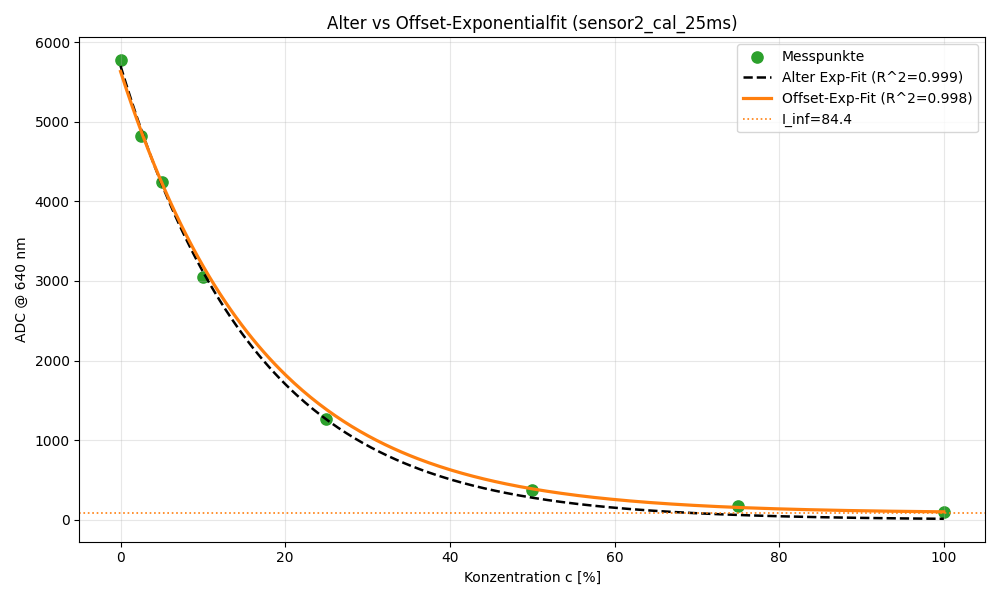

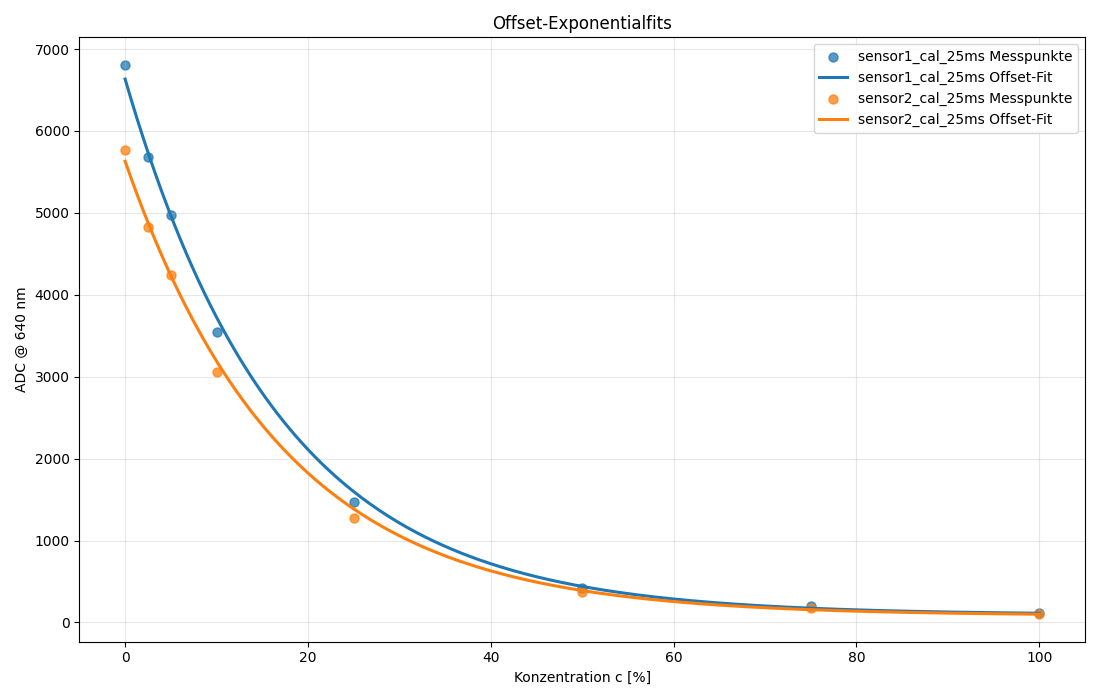


Offset-Exponentialfunktionen:
  sensor1_cal_25ms: I(c) = 94.8355 + (6633.1044 - 94.8355) * exp(-0.058805 * c) | R^2=0.9984, RMSE(c)=1.606 %
  sensor2_cal_25ms: I(c) = 84.3675 + (5630.6824 - 84.3675) * exp(-0.057966 * c) | R^2=0.9985, RMSE(c)=1.501 %


In [17]:
# Alternativer Exponentialfit mit Offset (Restsignal), robust und rueckrechnungsorientiert:
# I(c) = I_inf + (I0 - I_inf) * exp(-alpha * c)
# Wichtige Nebenbedingung: I_inf muss unter dem Signal bei hoechster Konzentration liegen.

from scipy.optimize import least_squares

if 'group_stats_by_sensor' not in globals() or not group_stats_by_sensor:
    raise RuntimeError('Bitte zuerst die Statistik-Zelle ausfuehren.')

if 'fit_results' not in globals() or not fit_results:
    raise RuntimeError('Bitte zuerst den bisherigen Exponentialfit ausfuehren.')

if 'marker_to_concentration_pct' not in globals():
    def marker_to_concentration_pct(marker: str) -> float:
        mk = str(marker).strip().upper()
        if mk in {'H20', 'H2O'}:
            return 0.0
        if mk == 'C002':
            return 2.5
        mm = re.match(r'^C(\d+)$', mk)
        if mm:
            return float(int(mm.group(1)))
        raise ValueError(f'Unbekannter Marker: {marker}')

def intensity_model_offset(c, I0, alpha, I_inf):
    return I_inf + (I0 - I_inf) * np.exp(-alpha * c)

def concentration_from_offset_model(I, I0, alpha, I_inf, clip_output=True, c_min=0.0, c_max=100.0):
    # c = -1/alpha * ln((I - I_inf)/(I0 - I_inf))
    num = np.clip(np.asarray(I, dtype=float) - I_inf, 1e-12, None)
    den = max(I0 - I_inf, 1e-12)
    ratio = np.clip(num / den, 1e-12, None)
    c = -np.log(ratio) / max(alpha, 1e-12)
    if clip_output:
        c = np.clip(c, c_min, c_max)
    return c

offset_fit_results = {}

# Gewichtung fuer kombiniertes Ziel: ADC-Fit + gute Rueckrechnung
lambda_adc = 1.0
lambda_c = 1.3

for sensor_key, group_stats in group_stats_by_sensor.items():
    bl = group_stats[['marker_group', 'mean']].copy()
    bl = bl.rename(columns={'marker_group': 'marker', 'mean': 'mean_adc'})
    bl['concentration_pct'] = bl['marker'].apply(marker_to_concentration_pct)
    bl = bl[bl['mean_adc'] > 0].copy().sort_values('concentration_pct')

    if len(bl) < 4:
        print(f"{sensor_key}: Zu wenige Punkte fuer Offset-Fit.")
        continue

    c_data = bl['concentration_pct'].to_numpy(dtype=float)
    I_data = bl['mean_adc'].to_numpy(dtype=float)

    # Physikalische Schranke fuer I_inf:
    # Asymptote muss unterhalb des Messsignals bei maximaler Konzentration liegen.
    idx_max_c = int(np.argmax(c_data))
    I_at_max_c = float(I_data[idx_max_c])
    iinf_upper = max(0.98 * I_at_max_c, 1e-6)

    I0_guess = float(np.max(I_data))
    alpha_guess = 0.05
    I_inf_guess = min(float(np.min(I_data)) * 0.7, 0.9 * I_at_max_c)

    scale_I = max(float(np.ptp(I_data)), 1.0)
    scale_c = max(float(np.ptp(c_data)), 1.0)

    def residuals(theta):
        I0, alpha, I_inf = map(float, theta)
        I_model = intensity_model_offset(c_data, I0, alpha, I_inf)
        r_adc = (I_model - I_data) / scale_I

        c_back_raw = concentration_from_offset_model(I_data, I0, alpha, I_inf, clip_output=False)
        r_c = (c_back_raw - c_data) / scale_c

        return np.concatenate([np.sqrt(lambda_adc) * r_adc, np.sqrt(lambda_c) * r_c])

    lower = np.array([0.5 * I0_guess, 1e-6, 0.0], dtype=float)
    upper = np.array([1.5 * I0_guess, 1.0, iinf_upper], dtype=float)
    x0 = np.array([I0_guess, alpha_guess, max(0.0, I_inf_guess)], dtype=float)

    res = least_squares(
        residuals,
        x0=x0,
        bounds=(lower, upper),
        loss='soft_l1',
        f_scale=1.0,
        max_nfev=50000,
    )

    I0_off, alpha_off, I_inf_off = map(float, res.x)

    I_fit_off = intensity_model_offset(c_data, I0_off, alpha_off, I_inf_off)
    sst = float(np.sum((I_data - np.mean(I_data)) ** 2))
    ssr = float(np.sum((I_data - I_fit_off) ** 2))
    r2_off = np.nan if sst == 0 else 1.0 - (ssr / sst)

    c_back_off_raw = concentration_from_offset_model(I_data, I0_off, alpha_off, I_inf_off, clip_output=False)
    c_back_off = concentration_from_offset_model(I_data, I0_off, alpha_off, I_inf_off, clip_output=True, c_min=0.0, c_max=100.0)
    c_err_off = c_back_off - c_data
    rmse_c_off = float(np.sqrt(np.mean(np.square(c_err_off))))

    c_back_old = None
    if sensor_key in fit_results:
        I0_old = float(fit_results[sensor_key]['I0'])
        alpha_old = float(fit_results[sensor_key]['alpha'])
        c_back_old = -np.log(np.clip(I_data / I0_old, 1e-12, None)) / max(alpha_old, 1e-12)
        c_back_old = np.clip(c_back_old, 0.0, 100.0)

    check = bl.copy()
    if c_back_old is not None:
        check['c_back_old_pct'] = c_back_old
        check['c_err_old_pct'] = c_back_old - c_data
    check['c_back_offset_raw_pct'] = c_back_off_raw
    check['c_back_offset_pct'] = c_back_off
    check['c_err_offset_pct'] = c_err_off

    offset_fit_results[sensor_key] = {
        'I0': I0_off,
        'alpha': alpha_off,
        'I_inf': I_inf_off,
        'r2_adc': r2_off,
        'rmse_c': rmse_c_off,
        'fit_function': f"I(c) = {I_inf_off:.4f} + ({I0_off:.4f} - {I_inf_off:.4f}) * exp(-{alpha_off:.6f} * c)",
    }

    print(f"\n{sensor_key} -> Offset-Exponentialfit (mit Schranke fuer I_inf)")
    print(f"  I(c) = {I_inf_off:.4f} + ({I0_off:.4f} - {I_inf_off:.4f}) * exp(-{alpha_off:.6f} * c)")
    print(f"  R^2(ADC)={r2_off:.4f}, RMSE(c, geclippt 0..100)={rmse_c_off:.3f} %")

    c100_row = check[check['concentration_pct'] >= 99.9]
    if not c100_row.empty:
        c100_off = float(c100_row['c_back_offset_pct'].iloc[0])
        c100_old_txt = 'n/a'
        if 'c_back_old_pct' in check.columns:
            c100_old_txt = f"{float(c100_row['c_back_old_pct'].iloc[0]):.2f}"
        print(f"  C100 Rueckrechnung alt/offset: {c100_old_txt} / {c100_off:.2f} %")

    display_cols = ['marker', 'concentration_pct', 'mean_adc']
    if 'c_back_old_pct' in check.columns:
        display_cols += ['c_back_old_pct', 'c_err_old_pct']
    display_cols += ['c_back_offset_raw_pct', 'c_back_offset_pct', 'c_err_offset_pct']
    display(check[display_cols])

    # Plot: Messpunkte + alter Fit + Offset-Fit
    xfit = np.linspace(float(np.min(c_data)), float(np.max(c_data)), 300)
    y_off = intensity_model_offset(xfit, I0_off, alpha_off, I_inf_off)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(c_data, I_data, s=65, color='tab:green', label='Messpunkte')

    if sensor_key in fit_results:
        I0_old = float(fit_results[sensor_key]['I0'])
        alpha_old = float(fit_results[sensor_key]['alpha'])
        y_old = I0_old * np.exp(-alpha_old * xfit)
        ax.plot(xfit, y_old, 'k--', lw=1.8, label=f"Alter Exp-Fit (R^2={fit_results[sensor_key]['r2']:.3f})")

    ax.plot(xfit, y_off, color='tab:orange', lw=2.3, label=f"Offset-Exp-Fit (R^2={r2_off:.3f})")
    ax.axhline(I_inf_off, color='tab:orange', ls=':', lw=1.2, label=f'I_inf={I_inf_off:.1f}')

    ax.set_xlabel('Konzentration c [%]')
    ax.set_ylabel('ADC @ 640 nm')
    ax.set_title(f'Alter vs Offset-Exponentialfit ({sensor_key})')
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

if not offset_fit_results:
    raise RuntimeError('Kein Offset-Fit berechnet.')

# Gemeinsamer Plot aller Offset-Fits
fig, ax = plt.subplots(figsize=(11, 7))
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
for i, (sensor_key, vals) in enumerate(offset_fit_results.items()):
    color = colors[i % len(colors)]
    group_stats = group_stats_by_sensor[sensor_key]

    bl = group_stats[['marker_group', 'mean']].copy()
    bl = bl.rename(columns={'marker_group': 'marker', 'mean': 'mean_adc'})
    bl['concentration_pct'] = bl['marker'].apply(marker_to_concentration_pct)
    bl = bl[bl['mean_adc'] > 0].copy().sort_values('concentration_pct')

    c_data = bl['concentration_pct'].to_numpy(dtype=float)
    I_data = bl['mean_adc'].to_numpy(dtype=float)

    xfit = np.linspace(float(np.min(c_data)), float(np.max(c_data)), 300)
    yfit = intensity_model_offset(xfit, float(vals['I0']), float(vals['alpha']), float(vals['I_inf']))

    ax.scatter(c_data, I_data, s=42, color=color, alpha=0.75, label=f"{sensor_key} Messpunkte")
    ax.plot(xfit, yfit, color=color, lw=2.2, label=f"{sensor_key} Offset-Fit")

ax.set_xlabel('Konzentration c [%]')
ax.set_ylabel('ADC @ 640 nm')
ax.set_title('Offset-Exponentialfits')
ax.grid(True, alpha=0.3)
ax.legend(ncol=1)
plt.tight_layout()
plt.show()

print('\nOffset-Exponentialfunktionen:')
for sensor_key, vals in offset_fit_results.items():
    print(
        f"  {sensor_key}: I(c) = {vals['I_inf']:.4f} + ({vals['I0']:.4f} - {vals['I_inf']:.4f}) * exp(-{vals['alpha']:.6f} * c) "
        f"| R^2={vals['r2_adc']:.4f}, RMSE(c)={vals['rmse_c']:.3f} %"
    )

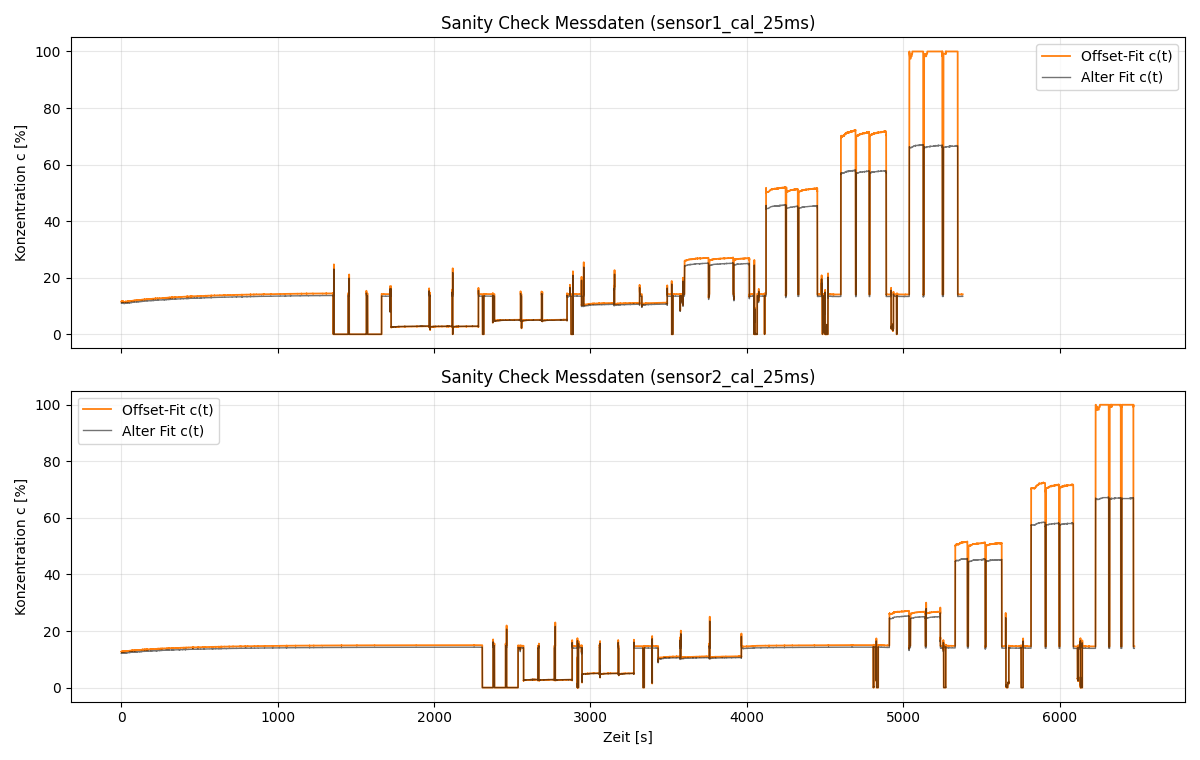

/var/folders/2q/_tgbc5bj1gd3yszdck0wkrjm0000gn/T/ipykernel_77972/326988034.py:79: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(len(offset_timeseries), 1, figsize=(12, 3.2 * len(offset_timeseries)), sharex=True)


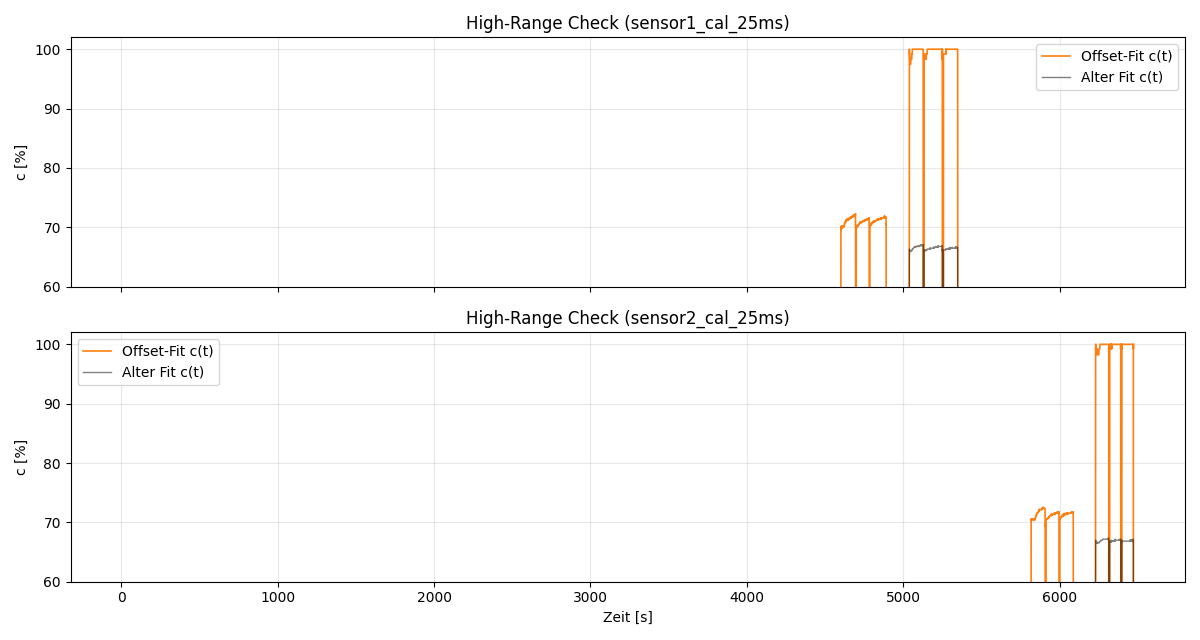


Offset-Fit Sanity Check (Kurzstatistik, hart begrenzt auf 0..100 %):
  sensor1_cal_25ms: n=71099, offset min/max/mean=0.00/100.00/21.65 %, old min/max/mean=0.00/67.06/18.26 %
  sensor2_cal_25ms: n=85043, offset min/max/mean=0.00/100.00/20.13 %, old min/max/mean=0.00/67.34/17.62 %


In [18]:
# Sanity Check: Offset-Fit auf 640-nm-Messdaten anwenden

if 'offset_fit_results' not in globals() or not offset_fit_results:
    raise RuntimeError('Bitte zuerst die Offset-Fit-Zelle ausfuehren.')
if 'sensor_keys' not in globals() or not sensor_keys:
    raise RuntimeError('sensor_keys nicht verfuegbar.')

offset_timeseries = {}

for sensor_key in sensor_keys:
    if sensor_key not in offset_fit_results:
        continue

    sensor_df = analyzer.datasets[sensor_key].copy()
    if 'device' in sensor_df.columns:
        sensor_df = sensor_df[sensor_df['device'] != 99].copy()

    if selected_wavelength not in sensor_df.columns:
        print(f"{sensor_key}: Wellenlaenge {selected_wavelength} nicht vorhanden.")
        continue

    ts = pd.to_numeric(sensor_df['timestamp'], errors='coerce')
    adc = pd.to_numeric(sensor_df[selected_wavelength], errors='coerce')

    fit = offset_fit_results[sensor_key]
    I0_off = float(fit['I0'])
    alpha_off = float(fit['alpha'])
    I_inf_off = float(fit['I_inf'])

    valid = ts.notna() & adc.notna() & (adc > 0)
    out = pd.DataFrame({
        'timestamp_s': ts[valid],
        'adc_640': adc[valid],
    }).sort_values('timestamp_s')

    # Rueckrechnung mit Offset-Modell, hart begrenzt auf 0..100 %
    out['conc_offset_pct'] = concentration_from_offset_model(
        out['adc_640'].to_numpy(dtype=float),
        I0_off,
        alpha_off,
        I_inf_off,
        clip_output=True,
        c_min=0.0,
        c_max=100.0,
    )

    # Optional Vergleich mit altem Fit (ebenfalls 0..100 % fuer fairen Vergleich)
    if 'fit_results' in globals() and sensor_key in fit_results:
        I0_old = float(fit_results[sensor_key]['I0'])
        alpha_old = float(fit_results[sensor_key]['alpha'])
        old_raw = -np.log(np.clip(out['adc_640'].to_numpy(dtype=float) / I0_old, 1e-12, None)) / max(alpha_old, 1e-12)
        out['conc_old_pct'] = np.clip(old_raw, 0.0, 100.0)

    offset_timeseries[sensor_key] = out

if not offset_timeseries:
    raise RuntimeError('Keine Zeitreihen fuer Offset-Sanity-Check erzeugt.')

# Plot 1: Offset-Rueckrechnung pro Sensor
fig, axes = plt.subplots(len(offset_timeseries), 1, figsize=(12, 3.8 * len(offset_timeseries)), sharex=True)
if len(offset_timeseries) == 1:
    axes = [axes]

for ax, (sensor_key, dfc) in zip(axes, offset_timeseries.items()):
    ax.plot(dfc['timestamp_s'], dfc['conc_offset_pct'], lw=1.3, color='tab:orange', label='Offset-Fit c(t)')
    if 'conc_old_pct' in dfc.columns:
        ax.plot(dfc['timestamp_s'], dfc['conc_old_pct'], lw=1.0, color='k', alpha=0.55, label='Alter Fit c(t)')

    ax.set_ylabel('Konzentration c [%]')
    ax.set_title(f'Sanity Check Messdaten ({sensor_key})')
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel('Zeit [s]')
plt.tight_layout()
plt.show()

# Plot 2: Zoom auf hohen Bereich (60..102 %) fuer C75/C100-Plausi
fig, axes = plt.subplots(len(offset_timeseries), 1, figsize=(12, 3.2 * len(offset_timeseries)), sharex=True)
if len(offset_timeseries) == 1:
    axes = [axes]

for ax, (sensor_key, dfc) in zip(axes, offset_timeseries.items()):
    ax.plot(dfc['timestamp_s'], dfc['conc_offset_pct'], lw=1.2, color='tab:orange', label='Offset-Fit c(t)')
    if 'conc_old_pct' in dfc.columns:
        ax.plot(dfc['timestamp_s'], dfc['conc_old_pct'], lw=1.0, color='k', alpha=0.5, label='Alter Fit c(t)')

    ax.set_ylim(60, 102)
    ax.set_ylabel('c [%]')
    ax.set_title(f'High-Range Check ({sensor_key})')
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel('Zeit [s]')
plt.tight_layout()
plt.show()

print('\nOffset-Fit Sanity Check (Kurzstatistik, hart begrenzt auf 0..100 %):')
for sensor_key, dfc in offset_timeseries.items():
    msg = (
        f"  {sensor_key}: n={len(dfc)}, "
        f"offset min/max/mean={dfc['conc_offset_pct'].min():.2f}/{dfc['conc_offset_pct'].max():.2f}/{dfc['conc_offset_pct'].mean():.2f} %"
    )
    if 'conc_old_pct' in dfc.columns:
        msg += (
            f", old min/max/mean={dfc['conc_old_pct'].min():.2f}/{dfc['conc_old_pct'].max():.2f}/{dfc['conc_old_pct'].mean():.2f} %"
        )
    print(msg)

# Steering auswertung
anwendung des fits auf die kalibrierten Sensor fits. Dabei ist
- 1000 = sensor1 (upstream)
- 1001 = sensor2 (downstream)
- 1003 = sensor3 (referenz)


In [19]:
# Steering-Auswertung fuer Messung E01_15x8_01
# 1) Drei Sensor-Rohdaten plotten (ab Step 6, Warm-up abgeschnitten)
# 2) Offset-Fit auf Rohdaten anwenden und Konzentration plotten (ab Step 6)
# 3) Markerlinien fuer Step 6, 8, 12, 14, 18, 20 einzeichnen

%matplotlib widget

import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Datei-Pfade ---
file_paths = {
    "sensor_1000": "Data/E01_15x8_01/SpectralSensor 1_20260423_161152.csv",
    "sensor_1001": "Data/E01_15x8_01/SpectralSensor 2_20260423_161152.csv",
    "sensor_1002": "Data/E01_15x8_01/SpectralSensor 3_20260423_161152.csv",
    "marker": "Data/E01_15x8_01/Markers_20260423_161152.csv",
}

for name, p in file_paths.items():
    if not os.path.exists(p):
        raise FileNotFoundError(f"Datei nicht gefunden ({name}): {p}")

# --- Hilfsfunktionen ---
def _read_sensor_csv(path: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    df.columns = [str(c).strip() for c in df.columns]
    if "timestamp" not in df.columns:
        raise ValueError(f"Spalte 'timestamp' fehlt in {path}")
    df["timestamp"] = pd.to_numeric(df["timestamp"], errors="coerce")

    # Zahlenwerte in Spektralspalten robust parsen (wegen fuehrender Leerzeichen in CSV)
    for c in df.columns:
        if c not in ("sensor", "timestamp"):
            df[c] = pd.to_numeric(df[c], errors="coerce")

    df = df.dropna(subset=["timestamp"]).copy()
    return df


def _read_marker_csv_robust(path: str) -> pd.DataFrame:
    """Liest Marker-CSV robust ein, auch wenn 'label' unquotierte Kommas enthaelt."""
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        header = f.readline()  # skip header
        for line in f:
            line = line.rstrip("\n")
            parts = line.split(",", 2)  # nur die ersten zwei Kommas trennen
            if len(parts) < 3:
                continue
            marker_id, ts, label = parts
            rows.append({"marker_id": marker_id.strip(), "timestamp": ts.strip(), "label": label.strip()})

    mdf = pd.DataFrame(rows)
    if mdf.empty:
        return mdf

    mdf["timestamp"] = pd.to_numeric(mdf["timestamp"], errors="coerce")
    mdf = mdf.dropna(subset=["timestamp", "label"]).copy()
    return mdf


def c_from_offset_exponential(I, I0, alpha, I_inf, clip_output=True, c_min=0.0, c_max=100.0):
    """Invertiert I(c)=I_inf+(I0-I_inf)*exp(-alpha*c) zu c(I)."""
    I = np.asarray(I, dtype=float)
    denom = (I0 - I_inf)
    if not np.isfinite(denom) or denom <= 0 or alpha <= 0:
        return np.full_like(I, np.nan, dtype=float)

    arg = (I - I_inf) / denom
    arg = np.maximum(arg, 1e-12)
    c = -np.log(arg) / alpha

    if clip_output:
        c = np.clip(c, c_min, c_max)
    return c


def _extract_step_number(label: str):
    m = re.search(r"STEP\s*[_-]?\s*(\d+)", str(label), flags=re.IGNORECASE)
    return int(m.group(1)) if m else None


# --- Daten laden ---
raw_data = {k: _read_sensor_csv(p) for k, p in file_paths.items() if k.startswith("sensor_")}
marker_df = _read_marker_csv_robust(file_paths["marker"]) if os.path.exists(file_paths["marker"]) else None

# Gemeinsame Zeitachse (in Minuten)
all_t0 = min(df["timestamp"].min() for df in raw_data.values())
for k in raw_data:
    raw_data[k]["time_min"] = (raw_data[k]["timestamp"] - all_t0) / 60000.0

# --- Marker/Steps aufbereiten ---
steps_to_draw = [6, 8, 12, 14, 18, 20]
step_ts = {}
if marker_df is not None and not marker_df.empty:
    mdf = marker_df.copy()
    mdf["step_num"] = mdf["label"].map(_extract_step_number)
    mdf = mdf.dropna(subset=["step_num"]).copy()
    mdf["step_num"] = mdf["step_num"].astype(int)

    # Falls ein Step mehrfach vorkommt: den ersten Zeitstempel verwenden
    for s in sorted(mdf["step_num"].unique()):
        ts_vals = mdf.loc[mdf["step_num"] == s, "timestamp"].to_numpy(dtype=float)
        if ts_vals.size > 0:
            step_ts[s] = float(np.min(ts_vals))

if 6 not in step_ts:
    found = sorted(step_ts.keys())
    raise RuntimeError(f"Step 6 wurde in der Marker-Datei nicht gefunden. Erkannte Steps: {found}")

step6_ts = step_ts[6]

# Nur Daten ab Step 6 behalten
raw_data_cut = {}
for k, df in raw_data.items():
    d = df.loc[df["timestamp"] >= step6_ts].copy()
    d["time_min_from_step6"] = (d["timestamp"] - step6_ts) / 60000.0
    raw_data_cut[k] = d

# Marker-Zeiten relativ zu Step 6
step_time_min = {}
for s in steps_to_draw:
    if s in step_ts:
        step_time_min[s] = (step_ts[s] - step6_ts) / 60000.0

# Wellenlaenge aus Kalibrierung verwenden, fallback 640 nm
wl = str(globals().get("selected_wavelength", "640"))
if wl not in next(iter(raw_data_cut.values())).columns:
    wl = "640"

# --- Plot 1: Rohdaten (drei Sensoren, ab Step 6) ---
sensor_label_map = {
    "sensor_1000": "Sensor 1000 (upstream)",
    "sensor_1001": "Sensor 1001 (downstream)",
    "sensor_1002": "Sensor 1002 (reference)",
}

colors = {
    "sensor_1000": "tab:blue",
    "sensor_1001": "tab:orange",
    "sensor_1002": "tab:green",
}

fig, ax = plt.subplots(figsize=(12, 4.8))
for k in ["sensor_1000", "sensor_1001", "sensor_1002"]:
    df = raw_data_cut[k]
    ax.plot(df["time_min_from_step6"], df[wl], lw=1.0, alpha=0.9, color=colors[k], label=sensor_label_map[k])

for s in steps_to_draw:
    if s in step_time_min:
        ax.axvline(step_time_min[s], color="k", linestyle=":" if s != 6 else "--", alpha=0.6, linewidth=1.0)
        ax.text(step_time_min[s], 0.98, f"S{s}", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=8)

ax.set_title(f"E01 Rohdaten @ {wl} nm (ab Step 6)")
ax.set_xlabel("Zeit ab Step 6 [min]")
ax.set_ylabel("ADC")
ax.grid(True, alpha=0.3)
ax.legend(loc="best")
plt.tight_layout()
plt.show()

# --- Offset-Fit-Zuordnung ---
if "offset_fit_results" not in globals() or not offset_fit_results:
    raise RuntimeError("offset_fit_results fehlt. Bitte zuerst den Offset-Fit-Block der Kalibrierung ausfuehren.")

# Annahme: sensor0->1000, sensor1->1001, sensor2->1002
fit_key_map = {
    "sensor_1000": "sensor0_cal_25ms",
    "sensor_1001": "sensor1_cal_25ms",
    "sensor_1002": "sensor2_cal_25ms",
}

# --- Offset-Fit auf Rohdaten anwenden (ab Step 6) ---
offset_conc = {}
summary_rows = []
for sk in ["sensor_1000", "sensor_1001", "sensor_1002"]:
    fk = fit_key_map[sk]
    if fk not in offset_fit_results:
        raise KeyError(f"Offset-Fit '{fk}' nicht in offset_fit_results gefunden.")

    fit = offset_fit_results[fk]
    I0 = float(fit["I0"])
    alpha = float(fit["alpha"])
    I_inf = float(fit["I_inf"])

    I_raw = raw_data_cut[sk][wl].to_numpy(dtype=float)
    c_raw = c_from_offset_exponential(I_raw, I0=I0, alpha=alpha, I_inf=I_inf, clip_output=True, c_min=0.0, c_max=100.0)
    offset_conc[sk] = c_raw

    summary_rows.append(
        {
            "sensor": sensor_label_map[sk],
            "fit_key": fk,
            "I0": I0,
            "alpha": alpha,
            "I_inf": I_inf,
            "c_min_pct": float(np.nanmin(c_raw)),
            "c_max_pct": float(np.nanmax(c_raw)),
            "c_mean_pct": float(np.nanmean(c_raw)),
        }
    )

# --- Plot 2: Offset-Fit Konzentration (drei Sensoren, ab Step 6) ---
fig, ax = plt.subplots(figsize=(12, 4.8))
for sk in ["sensor_1000", "sensor_1001", "sensor_1002"]:
    df = raw_data_cut[sk]
    ax.plot(df["time_min_from_step6"], offset_conc[sk], lw=1.0, alpha=0.95, color=colors[sk], label=sensor_label_map[sk])

for s in steps_to_draw:
    if s in step_time_min:
        ax.axvline(step_time_min[s], color="k", linestyle=":" if s != 6 else "--", alpha=0.6, linewidth=1.0)
        ax.text(step_time_min[s], 0.98, f"S{s}", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=8)

ax.set_title(f"E01 Offset-Fit Konzentration @ {wl} nm (ab Step 6)")
ax.set_xlabel("Zeit ab Step 6 [min]")
ax.set_ylabel("Konzentration [%]")
ax.set_ylim(-2, 102)
ax.grid(True, alpha=0.3)
ax.legend(loc="best")
plt.tight_layout()
plt.show()

# --- Tabellarische Kurzstatistik ---
summary_df = pd.DataFrame(summary_rows)
print("Offset-Fit Anwendung auf Rohdaten ab Step 6 (Kurzstatistik):")
display(summary_df.round(4))

print("Gezeichnete Marker (Zeit ab Step 6 in min):")
marker_info = [{"step": s, "time_min_from_step6": step_time_min[s]} for s in steps_to_draw if s in step_time_min]
display(pd.DataFrame(marker_info).round(3))

FileNotFoundError: Datei nicht gefunden (sensor_1000): Data/E01_15x8_01/SpectralSensor 1_20260423_161152.csv

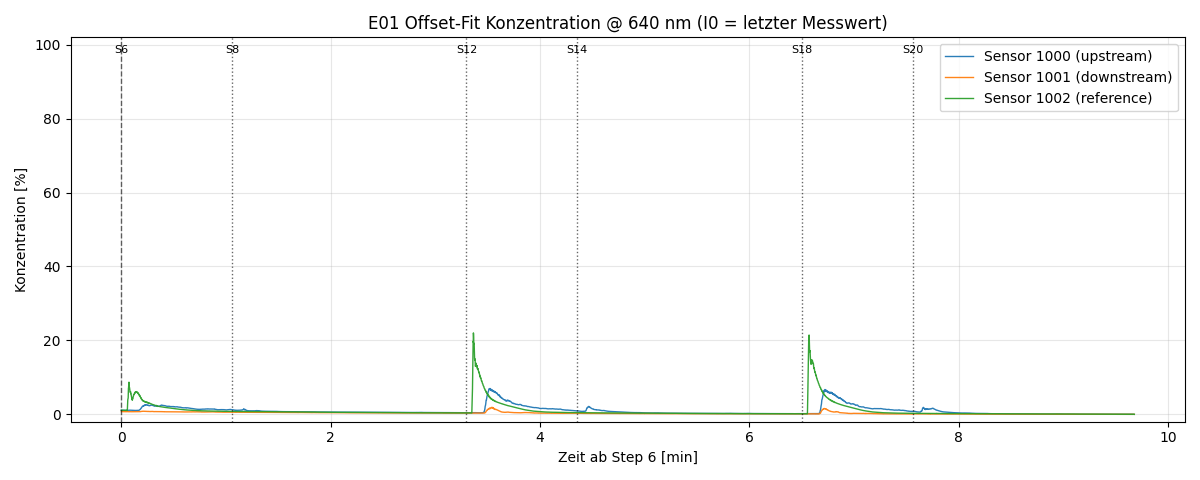

Offset-Fit mit messungsangepasstem I0 (letzter Messwert je Sensor):


,sensor,fit_key,I0_last_from_measurement,alpha,I_inf,c_min_pct,c_max_pct,c_mean_pct
0,Sensor 1000 (upstream),sensor0_cal_25ms,7658.0,0.0601,73.7730,-0.0,7.0027,0.9716
1,Sensor 1001 (downstream),sensor1_cal_25ms,5619.0,0.0588,94.8355,-0.0,1.9104,0.3180
2,Sensor 1002 (reference),sensor2_cal_25ms,6264.0,0.0580,84.3675,-0.0,22.0271,1.0315


In [ ]:
# Sensor-Fit anpassen: I0 pro Sensor aus Messung (letzter Rohdatenwert)
# Verwendet alpha und I_inf aus offset_fit_results, ersetzt nur I0.

required_vars = [
    "raw_data_cut",
    "offset_fit_results",
    "fit_key_map",
    "sensor_label_map",
    "colors",
    "step_time_min",
    "steps_to_draw",
    "wl",
]
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise RuntimeError(
        "Fehlende Variablen aus vorherigem Steering-Block: " + ", ".join(missing_vars)
    )

adapted_offset_conc = {}
adapt_rows = []

for sk in ["sensor_1000", "sensor_1001", "sensor_1002"]:
    fk = fit_key_map[sk]
    if fk not in offset_fit_results:
        raise KeyError(f"Offset-Fit '{fk}' nicht in offset_fit_results gefunden.")

    fit = offset_fit_results[fk]
    alpha = float(fit["alpha"])
    I_inf = float(fit["I_inf"])

    I_series = raw_data_cut[sk][wl].to_numpy(dtype=float)
    I0_last = float(I_series[-1])

    c_adapt = c_from_offset_exponential(
        I_series,
        I0=I0_last,
        alpha=alpha,
        I_inf=I_inf,
        clip_output=True,
        c_min=0.0,
        c_max=100.0,
    )
    adapted_offset_conc[sk] = c_adapt

    adapt_rows.append(
        {
            "sensor": sensor_label_map[sk],
            "fit_key": fk,
            "I0_last_from_measurement": I0_last,
            "alpha": alpha,
            "I_inf": I_inf,
            "c_min_pct": float(np.nanmin(c_adapt)),
            "c_max_pct": float(np.nanmax(c_adapt)),
            "c_mean_pct": float(np.nanmean(c_adapt)),
        }
    )

# Plot: angepasster Offset-Fit (nur I0 ersetzt)
fig, ax = plt.subplots(figsize=(12, 4.8))
for sk in ["sensor_1000", "sensor_1001", "sensor_1002"]:
    df = raw_data_cut[sk]
    ax.plot(
        df["time_min_from_step6"],
        adapted_offset_conc[sk],
        lw=1.0,
        alpha=0.95,
        color=colors[sk],
        label=sensor_label_map[sk],
    )

for s in steps_to_draw:
    if s in step_time_min:
        ax.axvline(step_time_min[s], color="k", linestyle=":" if s != 6 else "--", alpha=0.6, linewidth=1.0)
        ax.text(step_time_min[s], 0.98, f"S{s}", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=8)

ax.set_title(f"E01 Offset-Fit Konzentration @ {wl} nm (I0 = letzter Messwert)")
ax.set_xlabel("Zeit ab Step 6 [min]")
ax.set_ylabel("Konzentration [%]")
ax.set_ylim(-2, 102)
ax.grid(True, alpha=0.3)
ax.legend(loc="best")
plt.tight_layout()
plt.show()

# Tabelle
adapt_df = pd.DataFrame(adapt_rows)
print("Offset-Fit mit messungsangepasstem I0 (letzter Messwert je Sensor):")
display(adapt_df.round(4))

In [ ]:
# split IRs 5 ml/min : Step 6-11, 10 ml/min : Step 12-17, 15 ml/min : Step 18-21
step_ranges = {
    "5 ml/min": (6, 11),
    "10 ml/min": (12, 17),
    "15 ml/min": (18, 21),
}

# E02 Referenzmessung

Refererenz Messung mit und ohne Magnet, ohne diesen zu verfahren.



In [ ]:
from pathlib import Path
import re
from IPython.display import Markdown, display


e02_dir = Path("Data/E02_15x8_02")
marker_path = e02_dir / "Markers_20260521_150712.csv"
protocol_path = e02_dir / "Protocol_20260521_150712.txt"

if not marker_path.exists() or not protocol_path.exists():
    raise FileNotFoundError("Marker- oder Protokolldatei fuer E02_15x8_02 fehlt.")

protocol_text = protocol_path.read_text(encoding="utf-8")

exp_match = re.search(r"Experiment Name:\s*(.*)", protocol_text)
start_match = re.search(r"Start Time:\s*(.*)", protocol_text)

experiment_name = exp_match.group(1).strip() if exp_match else "unbekannt"
start_time = start_match.group(1).strip() if start_match else "unbekannt"

sensor_band_match = re.search(r"Timeline Band:\s*(.*)", protocol_text)
sensor_band = sensor_band_match.group(1).strip() if sensor_band_match else "unbekannt"

sensor_names = re.findall(r"- Name:\s*(SpectralSensor\s+\d+)", protocol_text)
pump_names = re.findall(r"- Name:\s*(ISMATEC\s+\d+|NE500\s+\d+)", protocol_text)
robot_present = "Denso Cobotta" in protocol_text

marker_rows = []
with marker_path.open("r", encoding="utf-8") as f:
    next(f)
    for line in f:
        line = line.strip()
        if not line:
            continue
        marker_id, timestamp, label = line.split(",", 2)
        step_match = re.search(r"STEP[^0-9]*(\d+)", label, flags=re.IGNORECASE)
        step_no = int(step_match.group(1)) if step_match else None
        marker_rows.append({
            "marker_id": int(marker_id),
            "timestamp_ms": int(timestamp),
            "step": step_no,
            "label": label,
        })

marker_df_e02 = pd.DataFrame(marker_rows).sort_values("timestamp_ms").reset_index(drop=True)

if marker_df_e02.empty:
    raise RuntimeError("Keine Marker in E02_15x8_02 gefunden.")

first_ts = int(marker_df_e02["timestamp_ms"].iloc[0])
marker_df_e02["t_rel_s"] = (marker_df_e02["timestamp_ms"] - first_ts) / 1000.0
marker_df_e02["action"] = marker_df_e02["label"].str.replace(r"^STEP[^:]*:\s*", "", regex=True)

inject_df = marker_df_e02[marker_df_e02["action"].str.contains("Inject syringe", case=False, na=False)].copy()
wait_df = marker_df_e02[marker_df_e02["action"].str.contains("Wait", case=False, na=False)].copy()
move_df = marker_df_e02[marker_df_e02["action"].str.contains("Move robot", case=False, na=False)].copy()

peristaltic_rates = sorted(set(re.findall(r"Start peristaltic\s*\(([0-9.]+\s*ml/min)\)", "\n".join(marker_df_e02["action"].tolist()), flags=re.IGNORECASE)))
injection_rates = sorted(set(re.findall(r"@\s*([0-9.]+\s*ul/min)", "\n".join(inject_df["action"].tolist()), flags=re.IGNORECASE)))
wait_times = re.findall(r"wait\s*([0-9]+\s*s)", "\n".join(wait_df["action"].tolist()), flags=re.IGNORECASE)

summary_lines = [
    "## Kurzprotokoll E02_15x8_02",
    "",
    f"- Experiment: {experiment_name}",
    f"- Startzeit: {start_time}",
    f"- Datenordner: `{e02_dir}`",
    f"- Sensoren: {', '.join(sensor_names) if sensor_names else 'nicht erkannt'}",
    f"- Messband: {sensor_band}",
    f"- Pumpen: {', '.join(pump_names) if pump_names else 'nicht erkannt'}",
    f"- Roboter im Setup vorhanden: {'ja' if robot_present else 'nein'}",
    "",
    "### Kurzablauf",
    f"- {len(inject_df)} Injektionen erkannt",
    f"- Peristaltikrate: {', '.join(peristaltic_rates) if peristaltic_rates else 'nicht erkannt'}",
    f"- Injektionsrate: {', '.join(injection_rates) if injection_rates else 'nicht erkannt'}",
    f"- Wartephasen: {', '.join(wait_times) if wait_times else 'nicht erkannt'}",
    f"- Roboterbewegungen im Markerfile: {len(move_df)}",
    f"- Letzter Schritt: Step {int(marker_df_e02['step'].dropna().max())} ({marker_df_e02['action'].iloc[-1]})",
    "",
    "### Interpretation",
    "- Referenzmessung ohne verfahrenen Roboter; der Magnetzustand bleibt laut Abschnittsbeschreibung konstant.",
    "- Drei 100-uL-Injektionen bei 10 ml/min Peristaltik und 10 uL/min Spritzenrate vor der Roboterpositionierung, danach drei weitere Injektionen an Position `c15_on`.",
    "- Nach jeder Injektion erfolgt eine definierte Warte- bzw. Flush-Phase, am Ende werden alle Geraete gestoppt.",
]

display(Markdown("\n".join(summary_lines)))
display(marker_df_e02[["step", "t_rel_s", "action"]])


## Kurzprotokoll E02_15x8_02

- Experiment: Referenz Messung no Robot
- Startzeit: 2026-05-21T15:07:12.985323
- Datenordner: `Data/E02_15x8_02`
- Sensoren: SpectralSensor 1, SpectralSensor 2, SpectralSensor 3
- Messband: Band 9 (640 nm)
- Pumpen: ISMATEC 1, NE500 1
- Roboter im Setup vorhanden: ja

### Kurzablauf
- 6 Injektionen erkannt
- Peristaltikrate: 10.0 ml/min
- Injektionsrate: 10.0 ul/min
- Wartephasen: 60 s, 60 s, 60 s, 180 s, 180 s, 180 s
- Roboterbewegungen im Markerfile: 1
- Letzter Schritt: Step 19 (Stop all devices)

### Interpretation
- Referenzmessung ohne verfahrenen Roboter; der Magnetzustand bleibt laut Abschnittsbeschreibung konstant.
- Drei 100-uL-Injektionen bei 10 ml/min Peristaltik und 10 uL/min Spritzenrate vor der Roboterpositionierung, danach drei weitere Injektionen an Position `c15_on`.
- Nach jeder Injektion erfolgt eine definierte Warte- bzw. Flush-Phase, am Ende werden alle Geraete gestoppt.

,step,t_rel_s,action
0,1,0.000,"Start sensor (upstream, downstream, reference)"
1,2,0.251,Wait (20 min warum up)
2,1,205.446,"Start sensor (upstream, downstream, reference)"
3,2,332.890,Wait (20 min warum up)
4,3,1559.785,Start peristaltic (10.0 ml/min)
5,4,1560.874,Wait (wait 60 s)
6,5,1622.258,Inject syringe 100.0 ul @ 10.0 ul/min
7,6,1623.294,Wait (flush bifurcation 60 s)
8,7,1684.658,Inject syringe 100.0 ul @ 10.0 ul/min
9,8,1685.719,Wait (flush bifucration 60 s)


# Kurzprotokoll E02_15x8_02

- Experiment: Referenz Messung no Robot
- Startzeit: 2026-05-21T15:07:12.985323
- Datenordner: `Data/E02_15x8_02`
- Sensoren: SpectralSensor 1, SpectralSensor 2, SpectralSensor 3
- Messband: Band 9 (640 nm)
- Pumpen: ISMATEC 1, NE500 1
- Roboter im Setup vorhanden: ja

## Kurzablauf
- 6 Injektionen erkannt
- Peristaltikrate: 10.0 ml/min
- Injektionsrate: 10.0 ul/min
- Wartephasen: 60 s, 60 s, 60 s, 180 s, 180 s, 180 s
- Roboterbewegungen im Markerfile: 1
- Letzter Schritt: Step 19 (Stop all devices)

### Interpretation
- Referenzmessung ohne verfahrenen Roboter; der Magnetzustand bleibt laut Abschnittsbeschreibung konstant.
- Drei 100-uL-Injektionen bei 10 ml/min Peristaltik und 10 uL/min Spritzenrate vor der Roboterpositionierung, danach drei weitere Injektionen an Position `c15_on`.
- Nach jeder Injektion erfolgt eine definierte Warte- bzw. Flush-Phase, am Ende werden alle Geraete gestoppt.

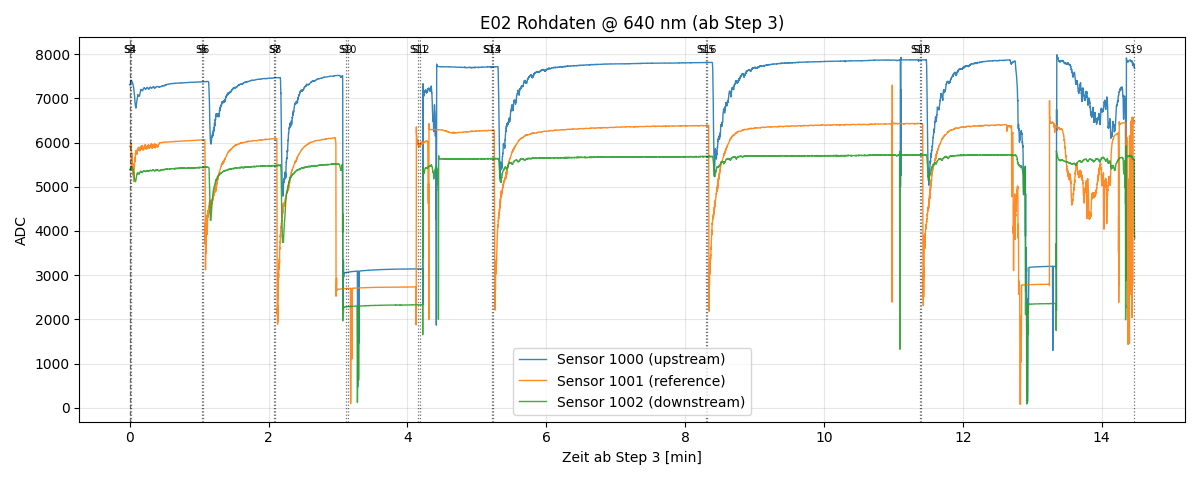

E02 Rohdaten geplottet (640 nm) mit 17 Markerlinien ab Step 3.


In [ ]:
# Plotten der Rohdaten von E02_15x8_02 mit Markern

%matplotlib widget

import os

required_helpers = ["_read_sensor_csv", "_read_marker_csv_robust", "_extract_step_number"]
missing_helpers = [name for name in required_helpers if name not in globals()]
if missing_helpers:
    raise RuntimeError(
        "Fehlende Hilfsfunktionen aus E01-Auswertung: " + ", ".join(missing_helpers)
    )

e02_file_paths = {
    "sensor_1000": "Data/E02_15x8_02/SpectralSensor 1_20260521_150712.csv",
    "sensor_1001": "Data/E02_15x8_02/SpectralSensor 2_20260521_150712.csv",
    "sensor_1002": "Data/E02_15x8_02/SpectralSensor 3_20260521_150712.csv",
    "marker": "Data/E02_15x8_02/Markers_20260521_150712.csv",
}

for name, p in e02_file_paths.items():
    if not os.path.exists(p):
        raise FileNotFoundError(f"Datei nicht gefunden ({name}): {p}")

e02_raw_data = {
    key: _read_sensor_csv(path)
    for key, path in e02_file_paths.items()
    if key.startswith("sensor_")
}
e02_marker_df = _read_marker_csv_robust(e02_file_paths["marker"])

for key, df in e02_raw_data.items():
    df["timestamp"] = pd.to_numeric(df["timestamp"], errors="coerce")

if e02_marker_df is None or e02_marker_df.empty:
    raise RuntimeError("Markerdatei fuer E02 ist leer oder konnte nicht gelesen werden.")

e02_marker_df = e02_marker_df.copy()
e02_marker_df["step_num"] = e02_marker_df["label"].map(_extract_step_number)
e02_marker_df = e02_marker_df.dropna(subset=["step_num", "timestamp"]).copy()
e02_marker_df["step_num"] = e02_marker_df["step_num"].astype(int)

step_ts_e02 = (
    e02_marker_df.sort_values("timestamp")
    .groupby("step_num", as_index=True)["timestamp"]
    .first()
    .to_dict()
)

# Wie bei E01 wird ein gemeinsamer Startpunkt definiert; fuer E02 ab erstem aktiven Pumpenschritt.
plot_start_step = 3
if plot_start_step not in step_ts_e02:
    raise RuntimeError(f"Step {plot_start_step} wurde in E02 nicht gefunden.")

plot_start_ts = float(step_ts_e02[plot_start_step])
steps_to_draw_e02 = [s for s in sorted(step_ts_e02) if s >= plot_start_step]

for key, df in e02_raw_data.items():
    cut = df.loc[df["timestamp"] >= plot_start_ts].copy()
    cut["time_min_from_step3"] = (cut["timestamp"] - plot_start_ts) / 60000.0
    e02_raw_data[key] = cut

step_time_min_e02 = {
    step: (float(ts) - plot_start_ts) / 60000.0
    for step, ts in step_ts_e02.items()
    if step in steps_to_draw_e02
}

wl_e02 = str(globals().get("selected_wavelength", "640"))
if wl_e02 not in next(iter(e02_raw_data.values())).columns:
    wl_e02 = "640"

# E02 hat eine andere Sensorzuordnung als E01, daher hier bewusst lokal festlegen.
sensor_label_map_e02 = {
    "sensor_1000": "Sensor 1000 (upstream)",
    "sensor_1001": "Sensor 1001 (reference)",
    "sensor_1002": "Sensor 1002 (downstream)",
}
colors_e02 = globals().get(
    "colors",
    {
        "sensor_1000": "tab:blue",
        "sensor_1001": "tab:orange",
        "sensor_1002": "tab:green",
    },
)

fig, ax = plt.subplots(figsize=(12, 4.8))
for key in ["sensor_1000", "sensor_1001", "sensor_1002"]:
    df = e02_raw_data[key]
    ax.plot(
        df["time_min_from_step3"],
        df[wl_e02],
        lw=1.0,
        alpha=0.9,
        color=colors_e02[key],
        label=sensor_label_map_e02[key],
    )

for step in steps_to_draw_e02:
    x = step_time_min_e02[step]
    ax.axvline(
        x,
        color="k",
        linestyle="--" if step == plot_start_step else ":",
        alpha=0.55,
        linewidth=0.9,
    )
    ax.text(
        x,
        0.98,
        f"S{step}",
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="top",
        fontsize=7,
    )

ax.set_title(f"E02 Rohdaten @ {wl_e02} nm (ab Step {plot_start_step})")
ax.set_xlabel(f"Zeit ab Step {plot_start_step} [min]")
ax.set_ylabel("ADC")
ax.grid(True, alpha=0.3)
ax.legend(loc="best")
plt.tight_layout()
plt.show()

print(f"E02 Rohdaten geplottet ({wl_e02} nm) mit {len(steps_to_draw_e02)} Markerlinien ab Step {plot_start_step}.")

,state,sensor,I_0pct,I_100pct,delta_I,slope_c_per_adc,intercept_pct,formula
0,nomag,Sensor 1000 (upstream),7500.0,138.0,-7362.0,-0.0136,101.8745,c(I) = 100 * (I_0 - I) / (I_0 - I_100)
1,nomag,Sensor 1001 (reference),6100.0,83.0,-6017.0,-0.0166,101.3794,c(I) = 100 * (I_0 - I) / (I_0 - I_100)
2,nomag,Sensor 1002 (downstream),5500.0,100.0,-5400.0,-0.0185,101.8519,c(I) = 100 * (I_0 - I) / (I_0 - I_100)
3,mag,Sensor 1000 (upstream),7850.0,138.0,-7712.0,-0.0130,101.7894,c(I) = 100 * (I_0 - I) / (I_0 - I_100)
4,mag,Sensor 1001 (reference),6400.0,83.0,-6317.0,-0.0158,101.3139,c(I) = 100 * (I_0 - I) / (I_0 - I_100)
5,mag,Sensor 1002 (downstream),5708.0,100.0,-5608.0,-0.0178,101.7832,c(I) = 100 * (I_0 - I) / (I_0 - I_100)


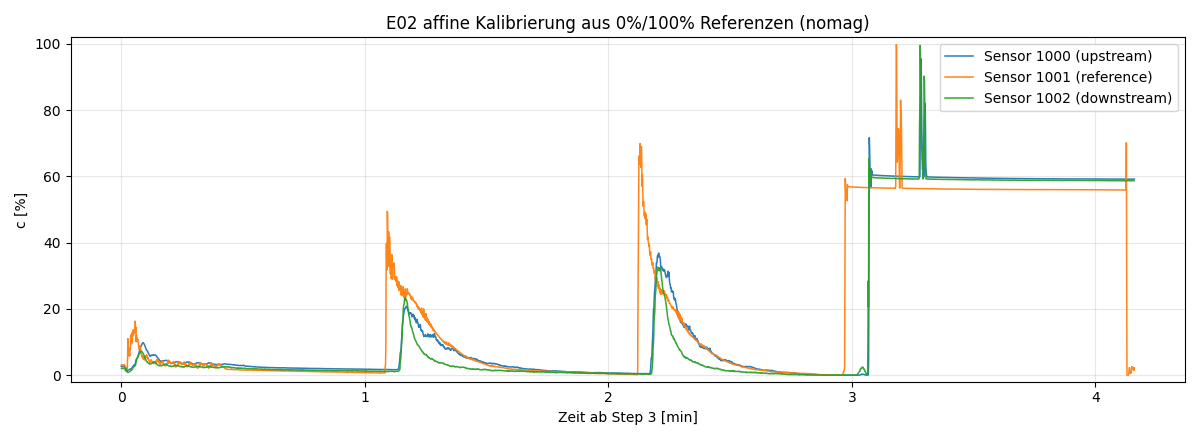

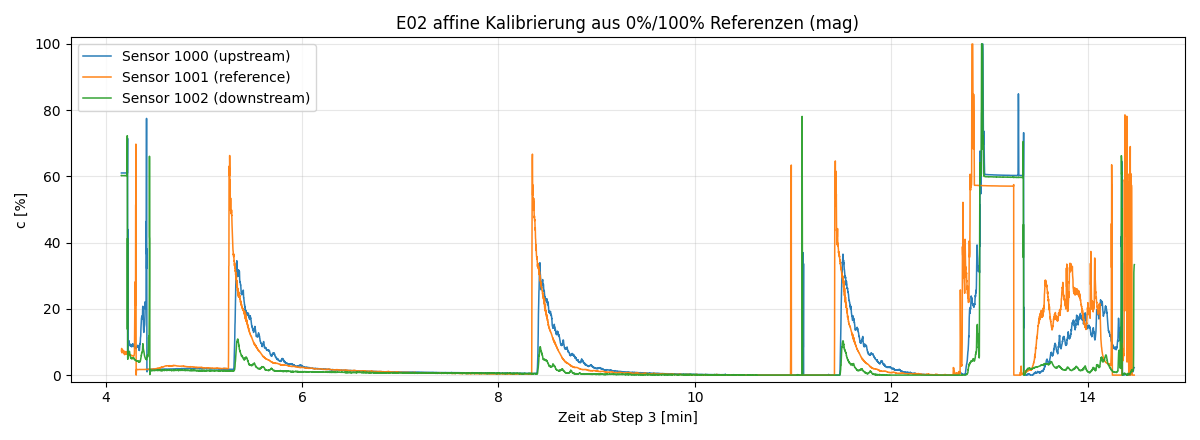

Affine Kalibrierparameter aus 0%/100%-Referenzen berechnet.


In [ ]:
# E02-Kalibrierkurve neu berechnen mit 0%- und 100%-Referenz je Zustand
# Hinweis: Die Referenzwerte sind fest vorgegeben und werden hier direkt verwendet.

if 'e02_raw_data' not in globals() or 'step_time_min_e02' not in globals():
    raise RuntimeError('E02 Rohdaten oder Schrittzeiten fehlen. Bitte zuerst die E02-Rohdatenzelle ausfuehren.')

split_step = 11
if split_step not in step_time_min_e02:
    raise RuntimeError(f'Step {split_step} wurde in E02 nicht gefunden und kann nicht als Trennpunkt genutzt werden.')

reference_values = {
    'nomag': {
        '100pct': {'sensor_1000': 138.0, 'sensor_1001': 83.0, 'sensor_1002': 100.0},
        '0pct': {'sensor_1000': 7500.0, 'sensor_1001': 6100.0, 'sensor_1002': 5500.0},
    },
    'mag': {
        '100pct': {'sensor_1000': 138.0, 'sensor_1001': 83.0, 'sensor_1002': 100.0},
        '0pct': {'sensor_1000': 7850.0, 'sensor_1001': 6400.0, 'sensor_1002': 5708.0},
    },
}

state_specs = {
    'nomag': {
        'start_step': plot_start_step,
        'end_step': split_step,
        'time_mask': lambda df: df['time_min_from_step3'] < step_time_min_e02[split_step],
    },
    'mag': {
        'start_step': split_step,
        'end_step': max(steps_to_draw_e02),
        'time_mask': lambda df: df['time_min_from_step3'] >= step_time_min_e02[split_step],
    },
}


def affine_c_from_0_100(I, I_0pct, I_100pct, clip_output=True):
    I = np.asarray(I, dtype=float)
    denom = float(I_0pct - I_100pct)
    if not np.isfinite(denom) or abs(denom) < 1e-12:
        return np.full_like(I, np.nan, dtype=float)
    c = 100.0 * (float(I_0pct) - I) / denom
    if clip_output:
        c = np.clip(c, 0.0, 100.0)
    return c

calibration_rows = []
calibration_timeseries = {}

for state_name, spec in state_specs.items():
    state_timeseries = {}
    for sensor_key in ['sensor_1000', 'sensor_1001', 'sensor_1002']:
        df = e02_raw_data[sensor_key]
        if wl_e02 not in df.columns:
            continue

        segment = df.loc[spec['time_mask'](df)].copy()
        if segment.empty:
            continue

        I_series = pd.to_numeric(segment[wl_e02], errors='coerce').dropna().to_numpy(dtype=float)
        if I_series.size < 2:
            continue

        ref_0pct = float(reference_values[state_name]['0pct'][sensor_key])
        ref_100pct = float(reference_values[state_name]['100pct'][sensor_key])
        if np.isclose(ref_0pct, ref_100pct):
            raise RuntimeError(f'Referenzwerte fuer {state_name}/{sensor_key} sind identisch und unbrauchbar.')

        slope = -100.0 / (ref_0pct - ref_100pct)
        intercept = 100.0 * ref_0pct / (ref_0pct - ref_100pct)

        c_affine = affine_c_from_0_100(segment[wl_e02].to_numpy(dtype=float), ref_0pct, ref_100pct, clip_output=True)
        state_timeseries[sensor_key] = pd.DataFrame(
            {
                'timestamp_s': pd.to_numeric(segment['timestamp'], errors='coerce'),
                'time_min': segment['time_min_from_step3'],
                'adc_640': segment[wl_e02].to_numpy(dtype=float),
                'c_affine_pct': c_affine,
            }
        ).dropna(subset=['timestamp_s', 'adc_640']).copy()

        calibration_rows.append(
            {
                'state': state_name,
                'sensor': sensor_label_map_e02[sensor_key],
                'I_0pct': ref_0pct,
                'I_100pct': ref_100pct,
                'delta_I': ref_100pct - ref_0pct,
                'slope_c_per_adc': slope,
                'intercept_pct': intercept,
                'formula': f'c(I) = 100 * (I_0 - I) / (I_0 - I_100)',
            }
        )

    calibration_timeseries[state_name] = state_timeseries

calibration_params_df = pd.DataFrame(calibration_rows)
display(calibration_params_df.round(4))

for state_name, state_timeseries in calibration_timeseries.items():
    if not state_timeseries:
        continue

    fig, ax = plt.subplots(figsize=(12, 4.4))
    for sensor_key, dfc in state_timeseries.items():
        ax.plot(
            dfc['time_min'],
            dfc['c_affine_pct'],
            lw=1.1,
            alpha=0.95,
            color=colors_e02[sensor_key],
            label=sensor_label_map_e02[sensor_key],
        )

    ax.set_title(f'E02 affine Kalibrierung aus 0%/100% Referenzen ({state_name})')
    ax.set_xlabel('Zeit ab Step 3 [min]')
    ax.set_ylabel('c [%]')
    ax.set_ylim(-2, 102)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best')
    plt.tight_layout()
    plt.show()

print('Affine Kalibrierparameter aus 0%/100%-Referenzen berechnet.')

# E02 Recalibrating 
## 100% Ref shot
- Sensor 1000 : 138
- Sensor 1001 : 83
- Sensor 1002 : 100

## 0% Ref no mag
- Sensor 1000 : 7500
- Sensor 1001 : 6100
- Sensor 1002 : 5500

## 0% Ref mag
- Sensor 1000 : 7850
- Sensor 1001 : 6400
- Sensor 1002 : 5708

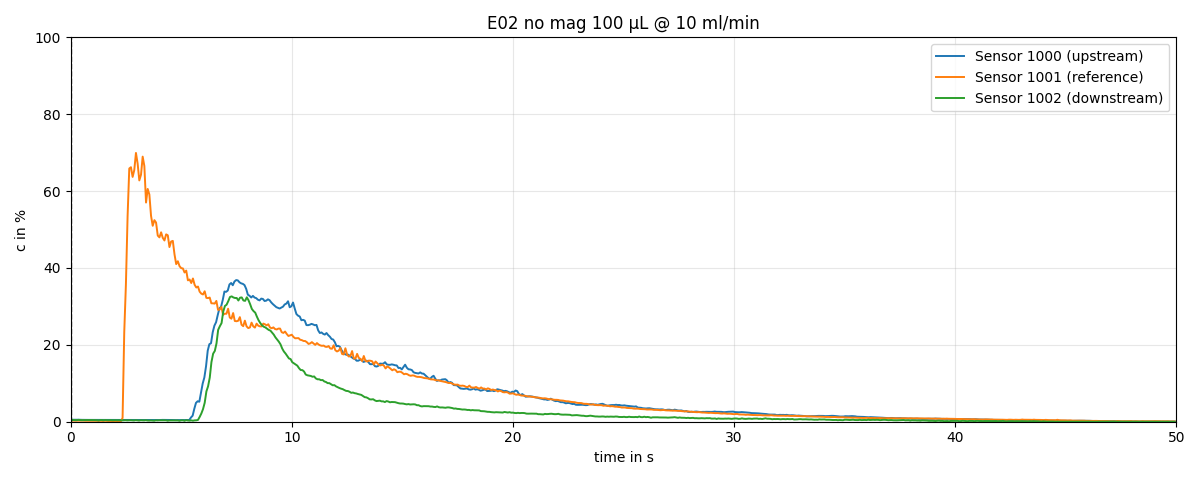

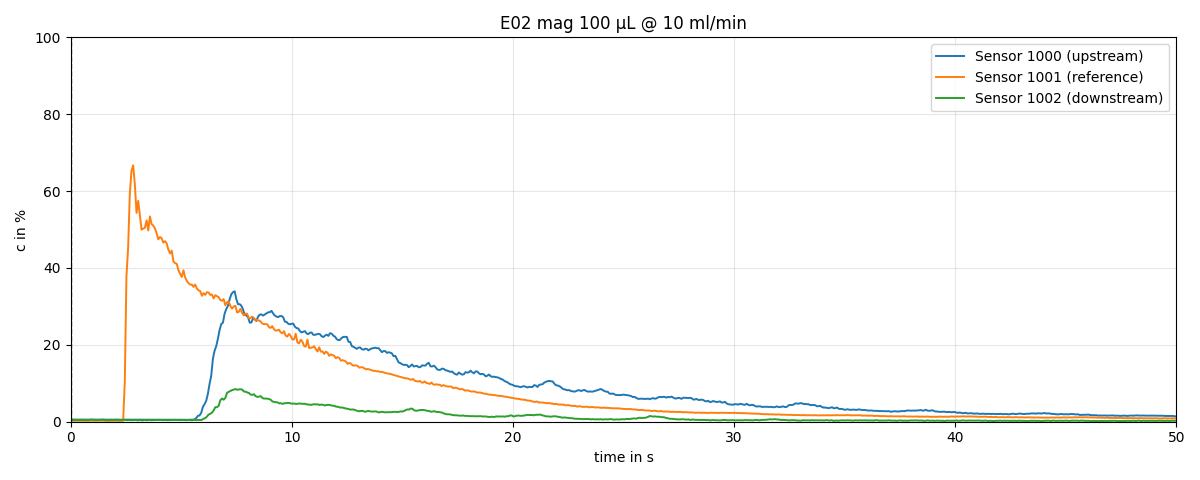

,plot,state,sensor,step,c_min_pct,c_max_pct,c_mean_pct
0,no mag,nomag,Sensor 1000 (upstream),7,0.0000,36.8514,6.6664
1,no mag,nomag,Sensor 1001 (reference),7,0.0831,69.9352,9.4868
2,no mag,nomag,Sensor 1002 (downstream),7,0.0000,32.6111,3.5741
3,mag,mag,Sensor 1000 (upstream),15,0.4927,33.9341,7.9784
4,mag,mag,Sensor 1001 (reference),15,0.2375,66.7247,9.1658
5,mag,mag,Sensor 1002 (downstream),15,0.1427,8.5235,1.3637


Zwei Einzelplots fuer no mag und mag wurden erzeugt.


In [ ]:
# Vergleich no mag vs mag
# Zwei Einzelplots: ab Step 7 fuer 60 s und ab Step 15 fuer 60 s
# y-Achse 0..100 %, x-Achse 0..60 s ab Marker

if 'e02_raw_data' not in globals() or 'step_ts_e02' not in globals():
    raise RuntimeError('E02 Rohdaten oder Markerzeiten fehlen. Bitte zuerst die E02-Rohdatenzelle ausfuehren.')
if 'wl_e02' not in globals():
    wl_e02 = '640'
if 'affine_c_from_0_100' not in globals():
    raise RuntimeError('Die affine E02-Kalibrierfunktion fehlt. Bitte zuerst die E02-Kalibrierzelle ausfuehren.')
if 'sensor_label_map_e02' not in globals() or 'colors_e02' not in globals():
    raise RuntimeError('E02 Sensorzuordnung oder Farben fehlen. Bitte zuerst die E02-Rohdatenzelle ausfuehren.')

compare_specs = [
    ('no mag', 'nomag', 7),
    ('mag', 'mag', 15),
]

reference_values = {
    'nomag': {
        '100pct': {'sensor_1000': 138.0, 'sensor_1001': 83.0, 'sensor_1002': 100.0},
        '0pct': {'sensor_1000': 7500.0, 'sensor_1001': 6100.0, 'sensor_1002': 5500.0},
    },
    'mag': {
        '100pct': {'sensor_1000': 138.0, 'sensor_1001': 83.0, 'sensor_1002': 100.0},
        '0pct': {'sensor_1000': 7850.0, 'sensor_1001': 6400.0, 'sensor_1002': 5708.0},
    },
}

comparison_rows = []

for plot_label, state_name, start_step in compare_specs:
    if start_step not in step_ts_e02:
        raise RuntimeError(f'Step {start_step} wurde in E02 nicht gefunden.')

    start_ts = float(step_ts_e02[start_step])
    end_ts = start_ts + 50.0 * 1000.0

    fig, ax = plt.subplots(figsize=(12, 4.8))

    for sensor_key in ['sensor_1000', 'sensor_1001', 'sensor_1002']:
        df = e02_raw_data[sensor_key]
        segment = df.loc[(df['timestamp'] >= start_ts) & (df['timestamp'] < end_ts)].copy()
        if segment.empty:
            continue

        segment['time_s_from_marker'] = (segment['timestamp'] - start_ts) / 1000.0
        ref_0pct = reference_values[state_name]['0pct'][sensor_key]
        ref_100pct = reference_values[state_name]['100pct'][sensor_key]
        segment['c_affine_pct'] = affine_c_from_0_100(
            segment[wl_e02].to_numpy(dtype=float),
            ref_0pct,
            ref_100pct,
            clip_output=True,
        )

        comparison_rows.append(
            {
                'plot': plot_label,
                'state': state_name,
                'sensor': sensor_label_map_e02[sensor_key],
                'step': start_step,
                'c_min_pct': float(np.nanmin(segment['c_affine_pct'].to_numpy(dtype=float))),
                'c_max_pct': float(np.nanmax(segment['c_affine_pct'].to_numpy(dtype=float))),
                'c_mean_pct': float(np.nanmean(segment['c_affine_pct'].to_numpy(dtype=float))),
            }
        )

        ax.plot(
            segment['time_s_from_marker'],
            segment['c_affine_pct'],
            lw=1.4,
            color=colors_e02[sensor_key],
            label=sensor_label_map_e02[sensor_key],
        )

    ax.axvline(0.0, color='k', ls='--', lw=1.0, alpha=0.7)
    ax.set_xlim(0, 50)
    ax.set_ylim(0, 100)
    ax.set_xlabel('time in s')
    ax.set_ylabel('c in %')
    ax.set_title(f'E02 {plot_label} 100 µL @ 10 ml/min')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best')
    plt.tight_layout()
    plt.show()

comparison_stats_df = pd.DataFrame(comparison_rows)
display(comparison_stats_df.round(4))

print('Zwei Einzelplots fuer no mag und mag wurden erzeugt.')